# Figure 5 — ExPert identifies mRNA export dysregulation in alcohol-associated liver disease

Renders panels B–G and I–M from the cached tables in `data/` (`data/final/` written by `fig5_final.py --stage data`;
`data/experiment_raw/` holds the collaborators' bulk RNA-seq tables, microscopy measurements and the RT-PCR gel
quantification) and the files linked in `inputs/` (snRNA-seq pseudobulk DE table, readout gene-set modules, Reactome GMT).
Panels go to `render/`, the source tables the plot functions write go to `render/src/`.

Not rendered (static artwork, no script draws them): **A** (study design schematic), **H** (poly(A) RNA-FISH
micrographs, `fig5h_RNA_FISH.svg`) and the gels on the left of **M** (`fig5m_SpliceAssay_gels.svg`).
`fig5g_bulk_volcano_alt` in the figure folder is an alternative version of G that is not in the figure.

In [1]:
import sys
from pathlib import Path
_paper = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'scripts' / 'common').is_dir())
sys.path.insert(0, str(_paper / 'scripts' / 'common'))
import nbtools as nb                      # puts paper/scripts/*/ on sys.path

vs = nb.vizstyle()
DATA, INPUTS, OUT, SRC = nb.folders()     # data/ (cache), inputs/, render/, render/src/

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import fig5_final as F
import fig5_bulk as B
import fig5i_fish as FISH
import fig5j_nuclei as NUC
import fig5m_psi as PSI

FINAL = DATA / 'final'                    # fig5_final.py --stage data
RAW = DATA / 'experiment_raw'             # bulk RNA-seq tables, microscopy, RT-PCR gel quantification
DEG = INPUTS / 'ald_snrna_pseudobulk_deg.csv.gz'
GMT = INPUTS / 'Enrichr.Reactome_Pathways_2024.gmt'
MODULES = INPUTS / 'readout_panels.tsv'

a = F.parser().parse_args(['--stage', 'plot', '--out-dir', str(FINAL), '--fig-dir', str(OUT), '--src-dir', str(SRC),
                           '--deg', str(DEG), '--reactome-gmt', str(GMT), '--modules', str(MODULES)])
c = F.plot_setup(a, vs)                   # style, ORA tables, gene sets; sets F.SRC = render/src
(rows_e, more_e, _), (rows_f, more_f, _) = F.collapsed_rows(c, a)   # E / F rows (hit-overlap folding)
b = B.parser().parse_args(['--bulk-dir', str(RAW / 'BulkRNASeqAnalysis' / 'tables'),
                           '--profiles', str(FINAL / 'fig5_profiles.npz'), '--fig-dir', str(OUT), '--src-dir', str(SRC),
                           '--modules', str(MODULES), '--reactome-gmt', str(GMT), '--vizstyle-root', str(nb.STYLE),
                           '--d-highlight', str(SRC / 'fig5d_volcano_highlight_genes.csv')])

## A — study design

Static schematic; not drawn by a script.

## B — UMAP of the nuclei in the ExPert latent, healthy vs ALD, with the top AC / AH prototypes

wrote fig5b_umap


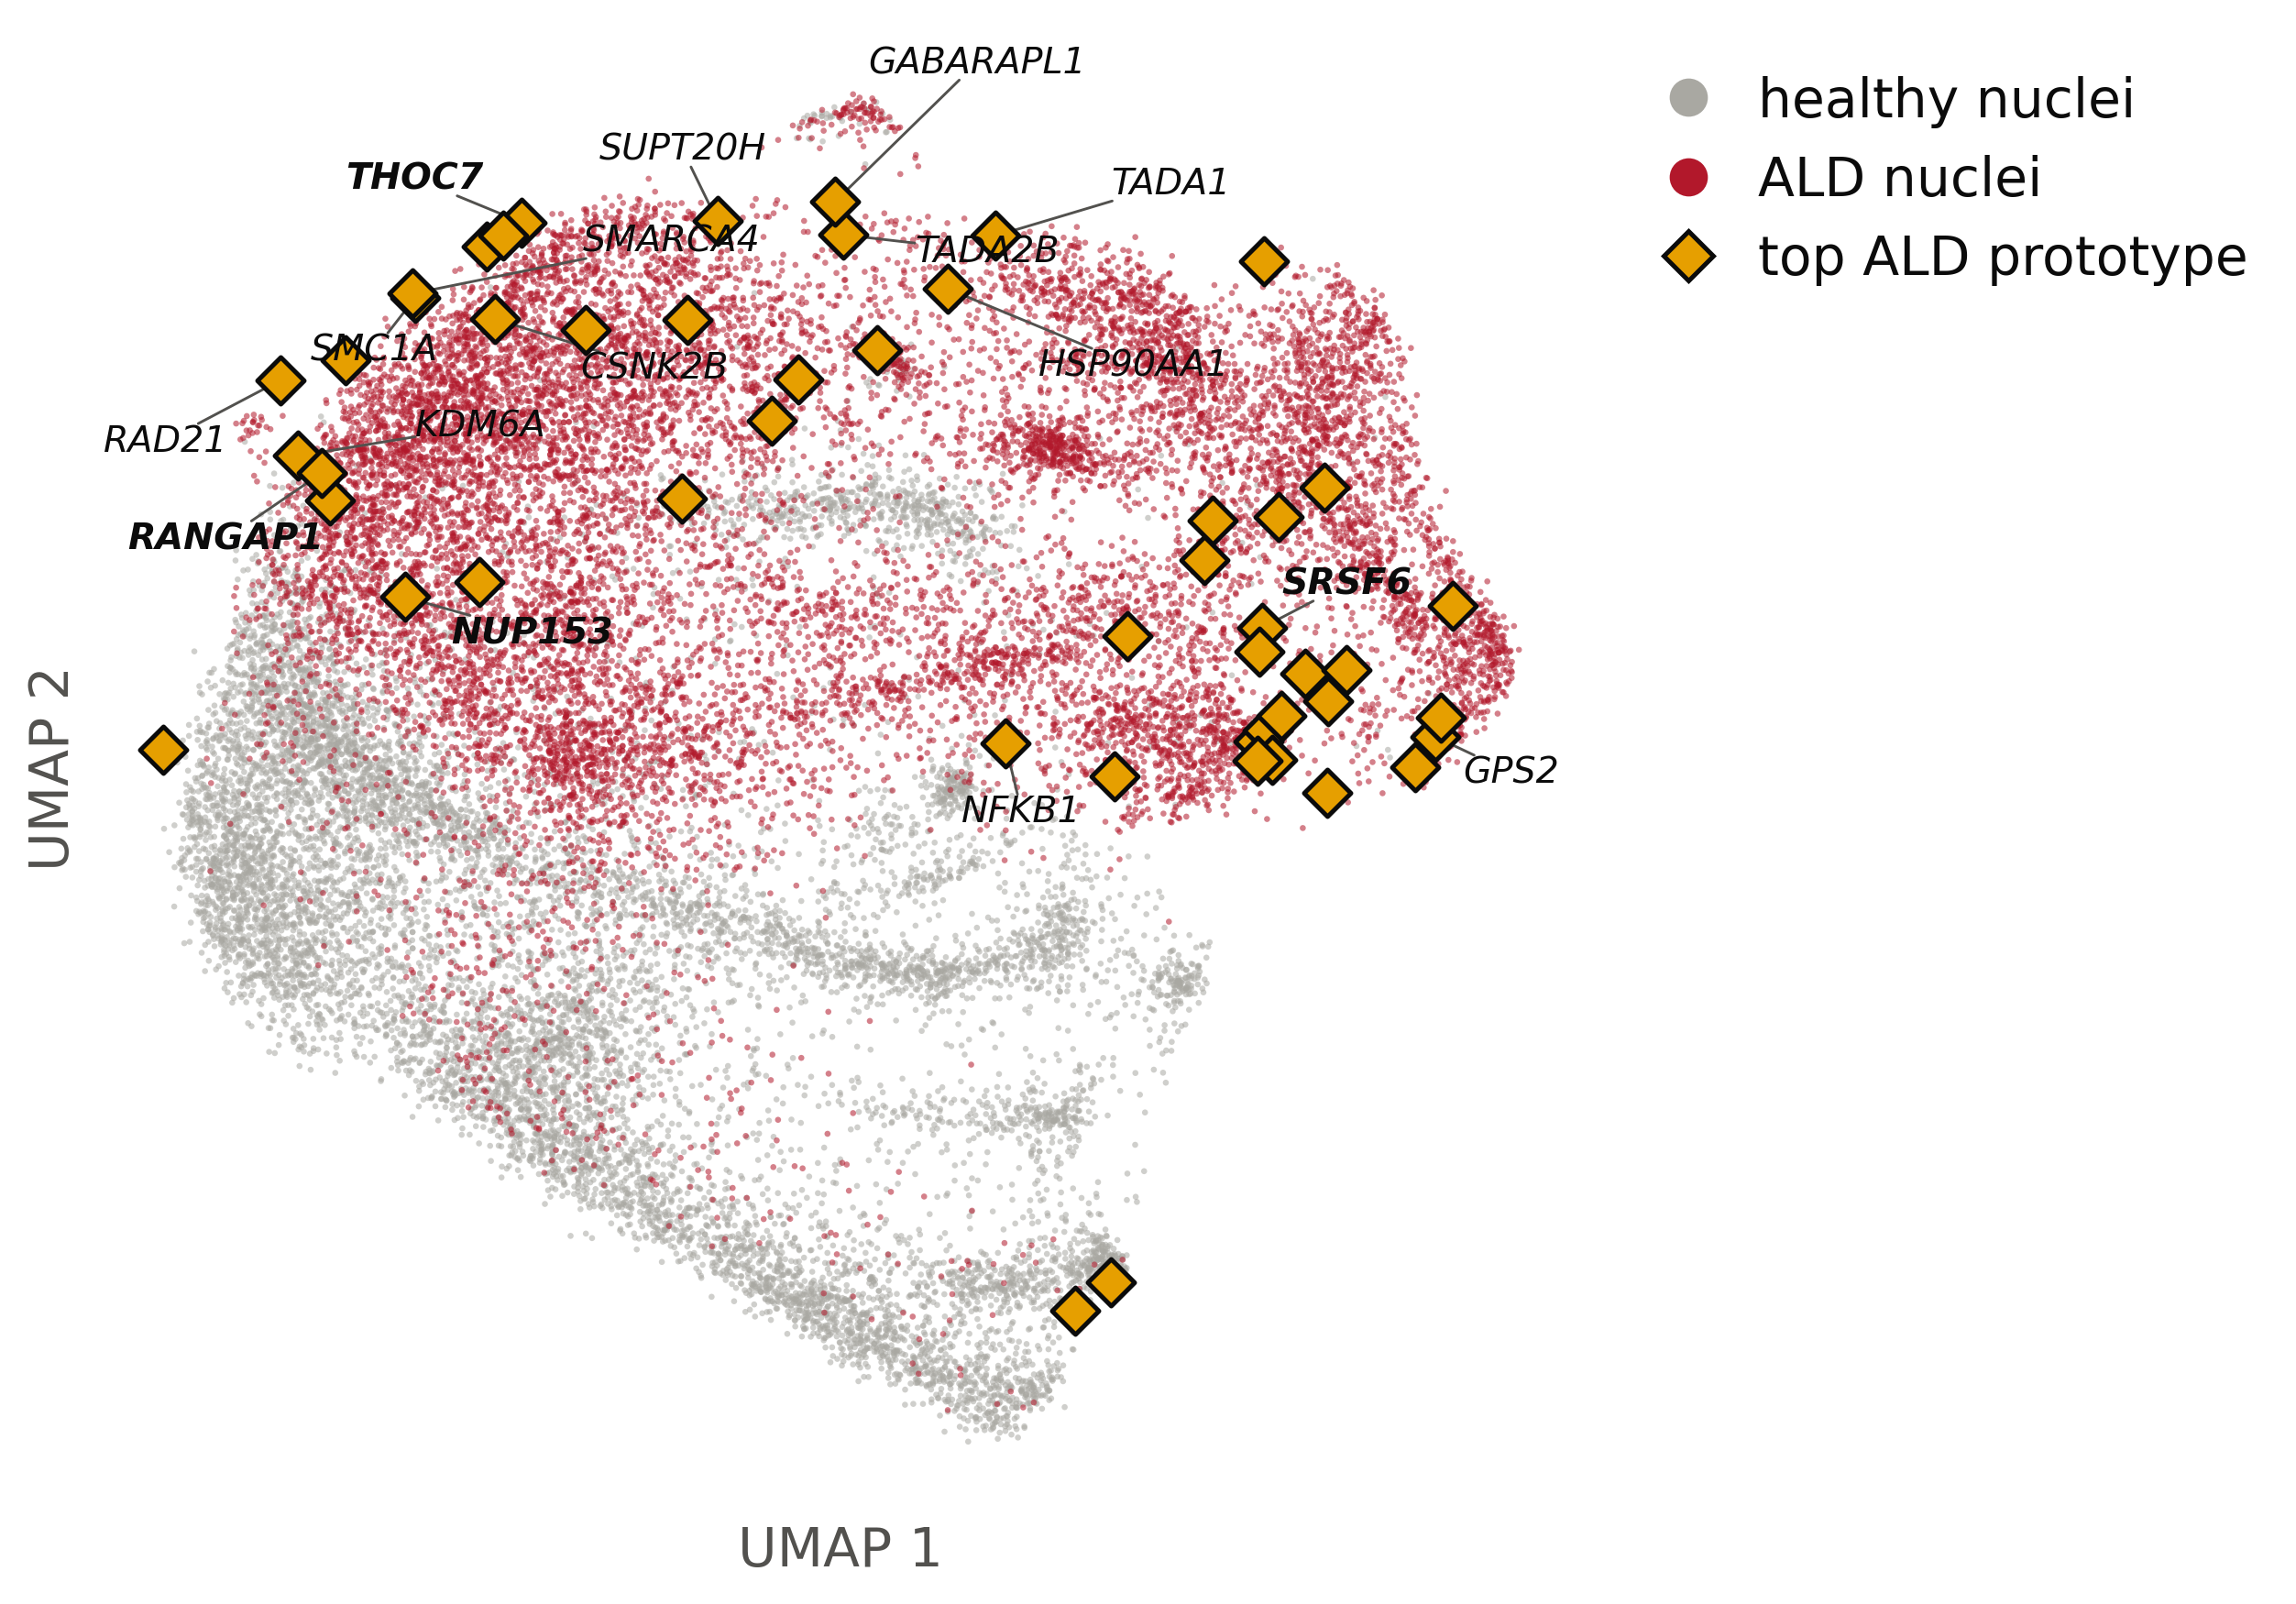

In [3]:
F.panel_umap(c, a)                        # also writes render/src/fig5b_umap_source.csv, read by D
nb.show(OUT, 'fig5b_umap')

## C — ExPert rank vs DE rank of the top 500 predictions (AC and AH hepatocytes)

wrote fig5c_orthogonality


        group  n_genes  shown    rho     p  median_de_rank_of_shown  shown_in_top_deg
AC|Hepatocyte     8333    500 -0.040 0.376                   4196.5                 9
AH|Hepatocyte     8333    500 -0.026 0.557                   4195.0                 8


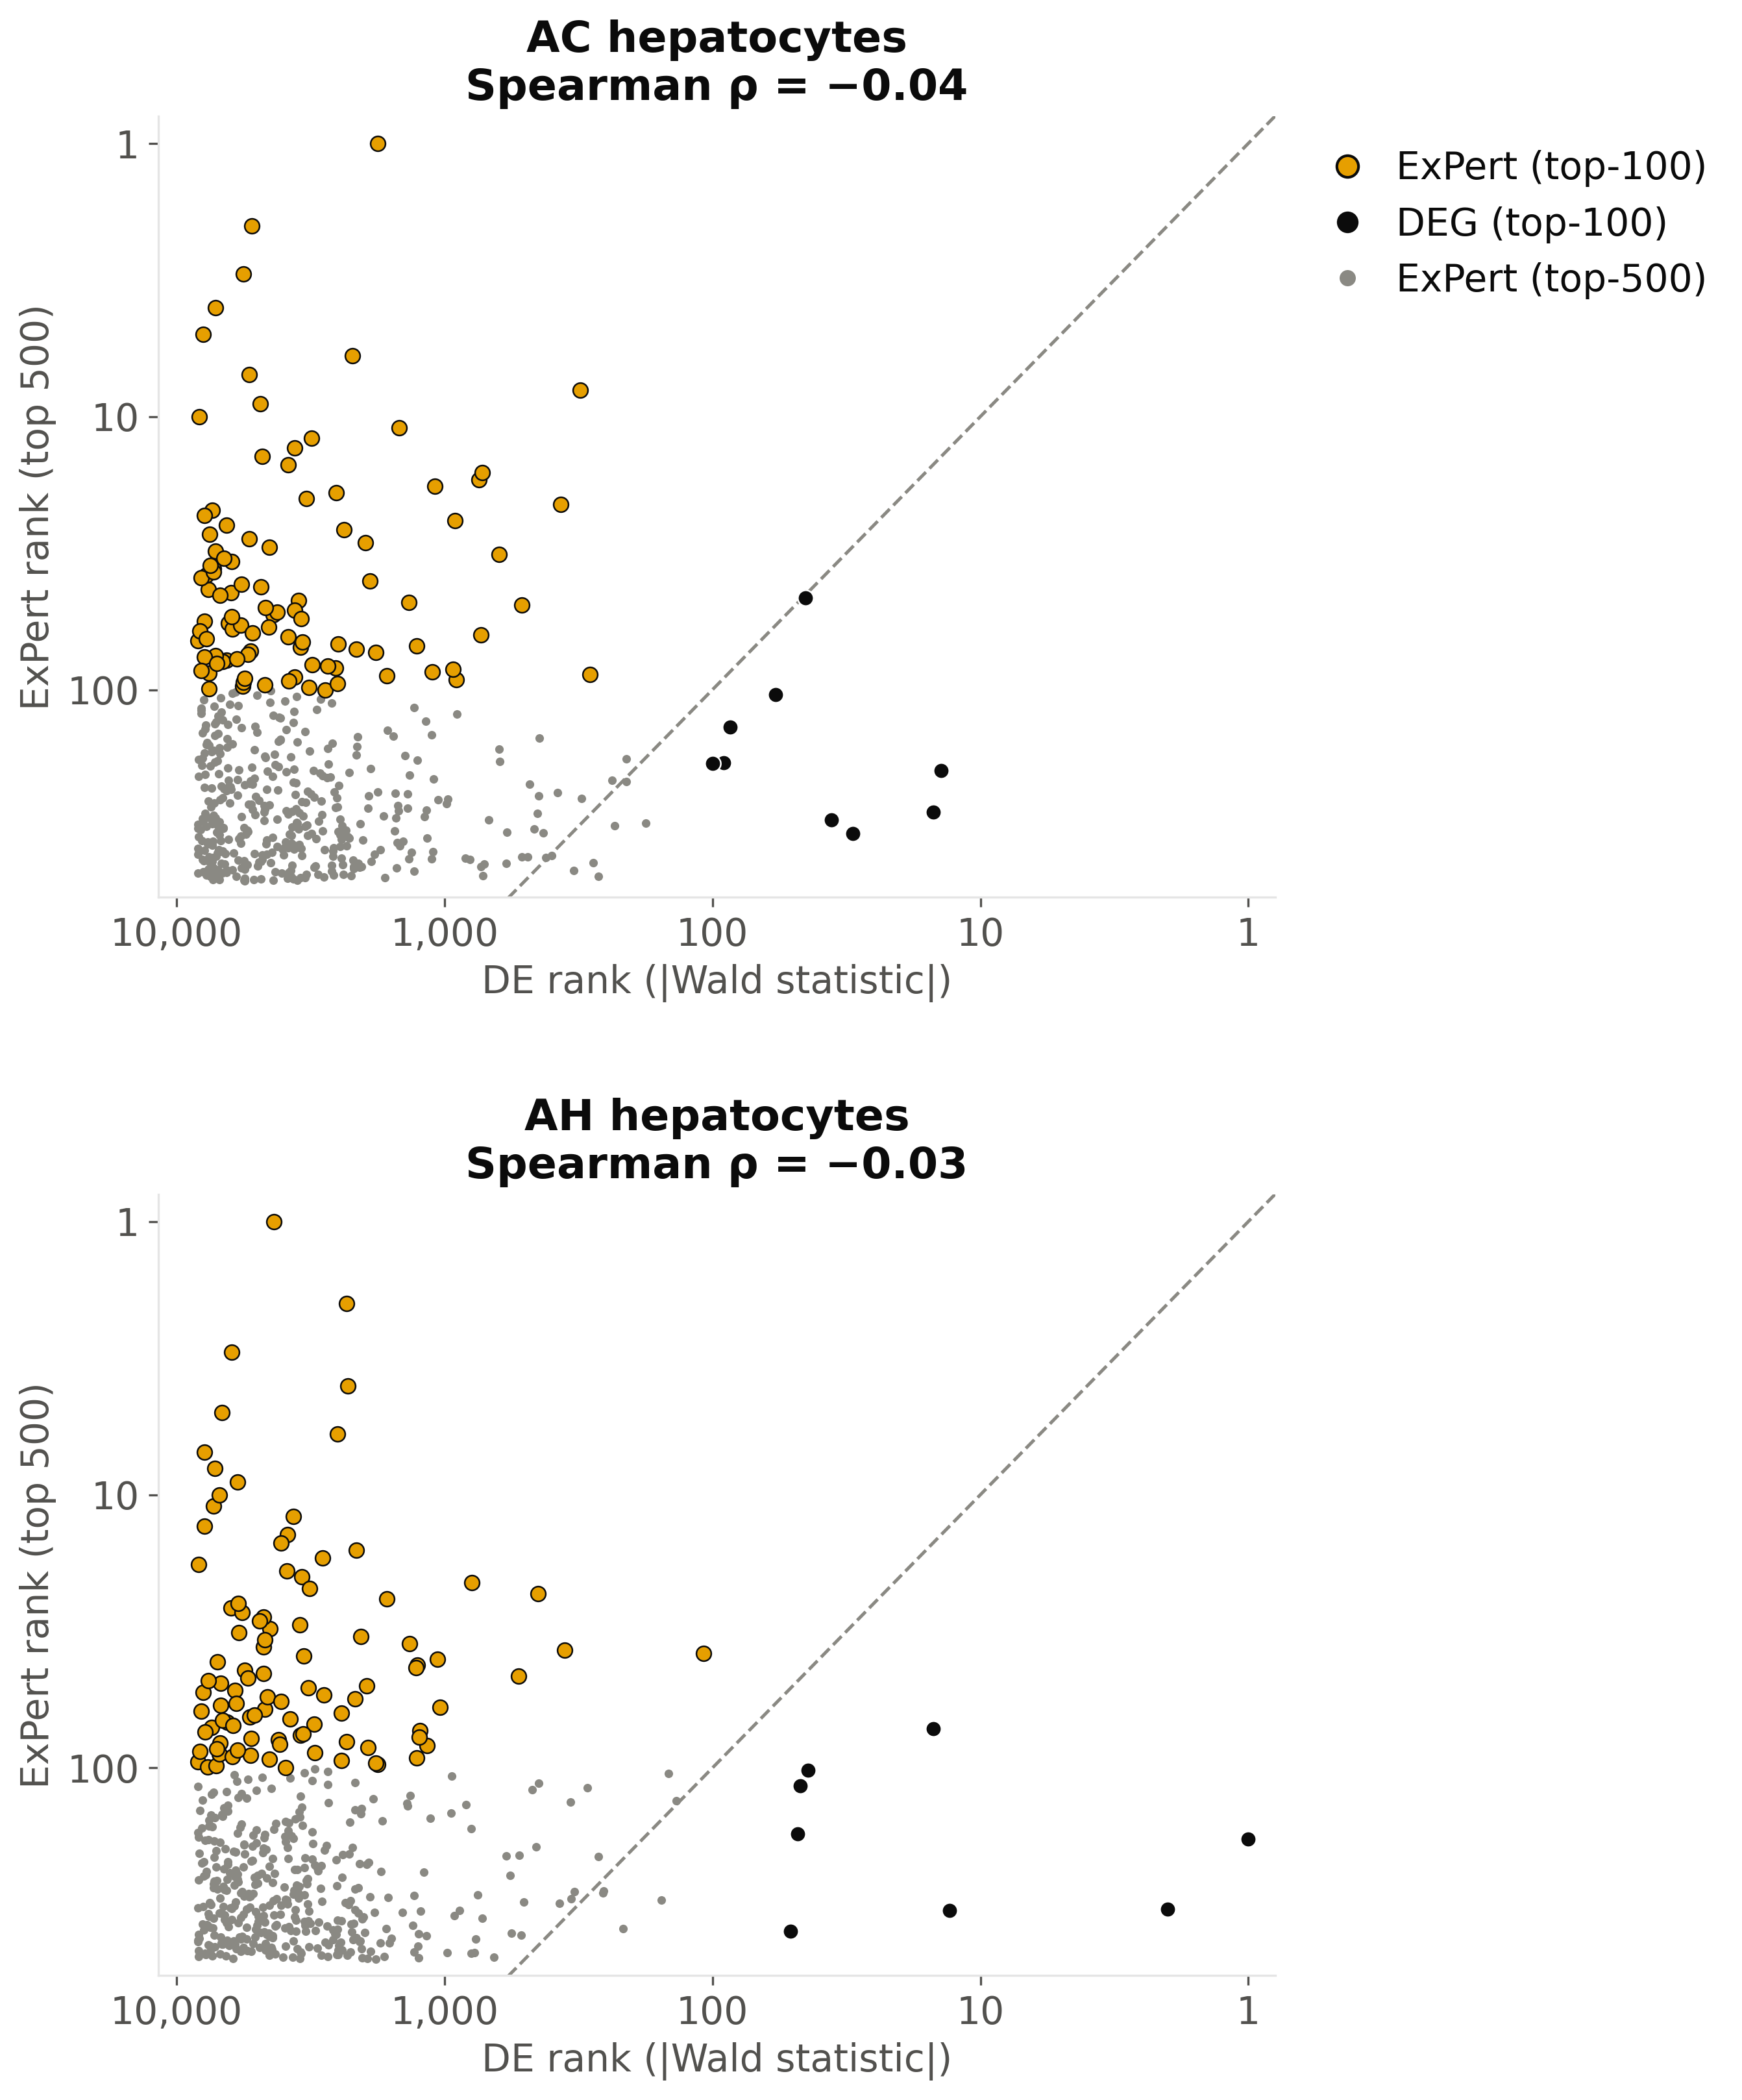

In [4]:
F.orth_stacked(vs, c.d, OUT, a, c.gs, c.cc)
nb.show(OUT, 'fig5c_orthogonality')

## D — hepatocyte pseudobulk DE volcanos (AC, AH vs healthy) with the top 100 DEGs and ExPert predictions

wrote fig5d_volcano


        group  top_n  n_deg  top_deg  top_model  model_in_table  model_that_are_DEGs  model_pass_p  model_pass_lfc  overlap
AC|Hepatocyte    100    649      100        100             100                    1             6               1        0
AH|Hepatocyte    100    588      100        100             100                    1             3               1        1


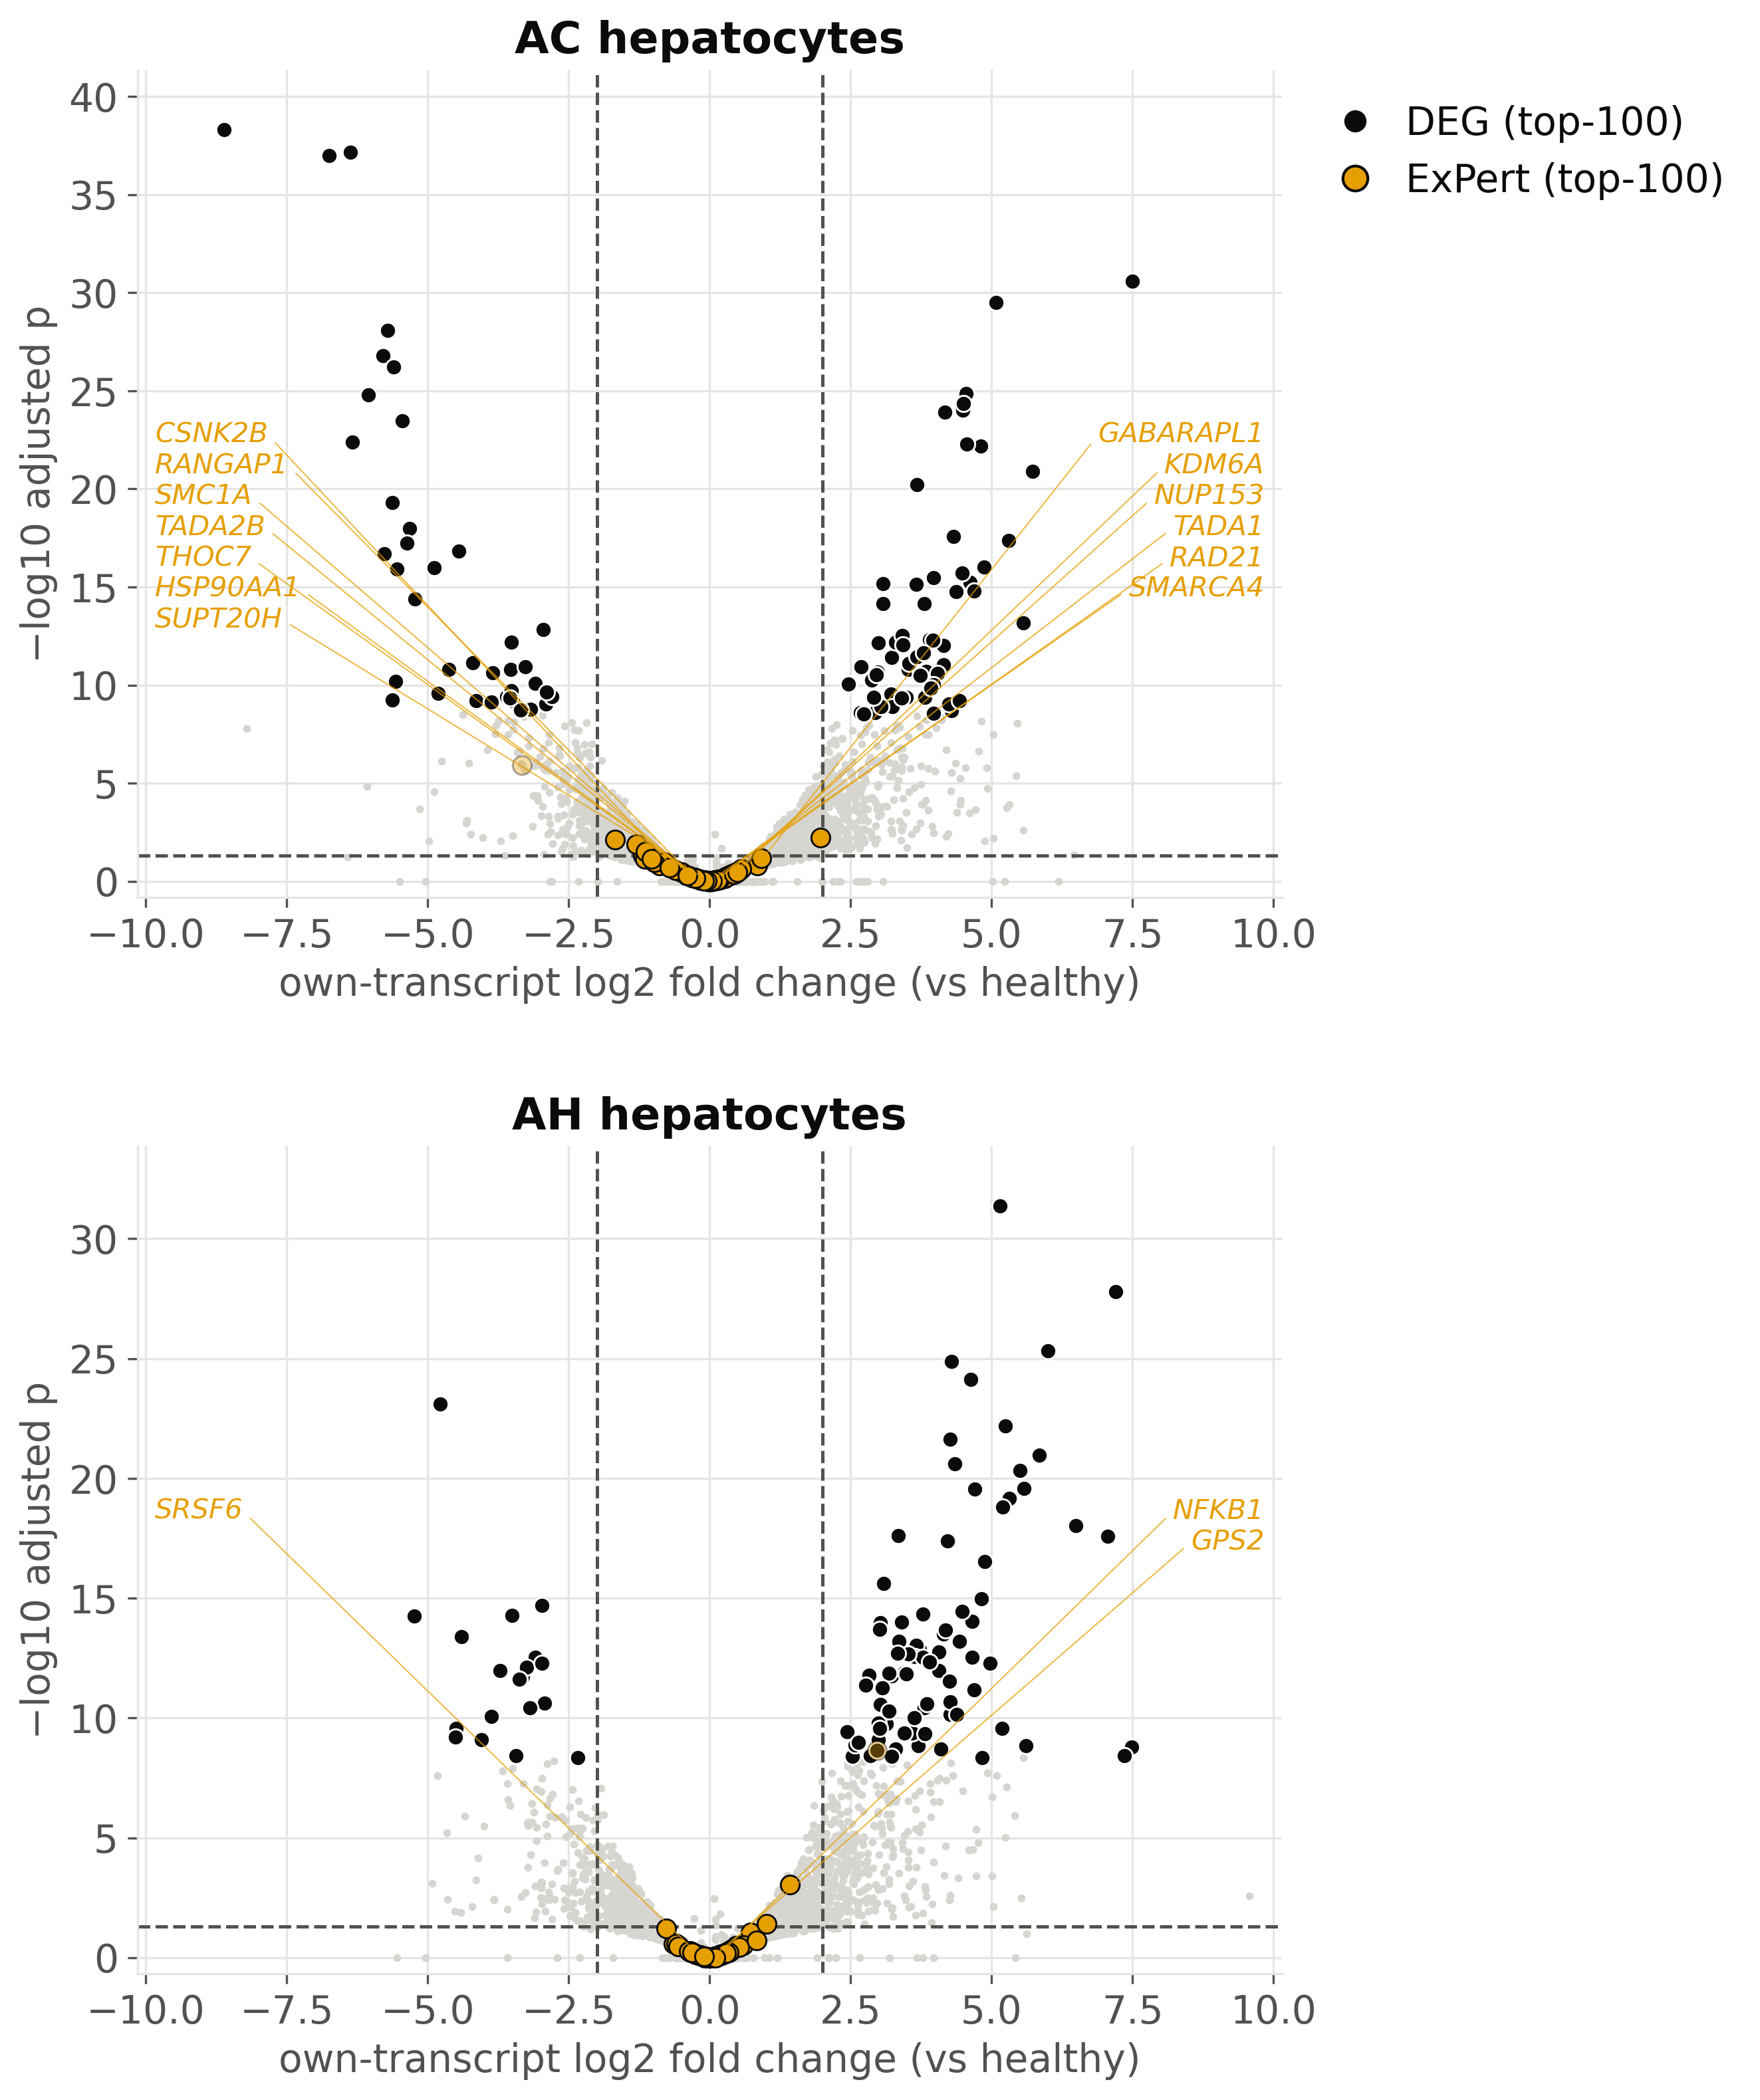

In [5]:
F.volcano(vs, c.d, OUT, a, a.d_groups, 'fig5d_volcano')
nb.show(OUT, 'fig5d_volcano')

## E — pathways enriched among the top 200 ExPert predictions, healthy and ALD hepatocytes

wrote fig5e_pathways


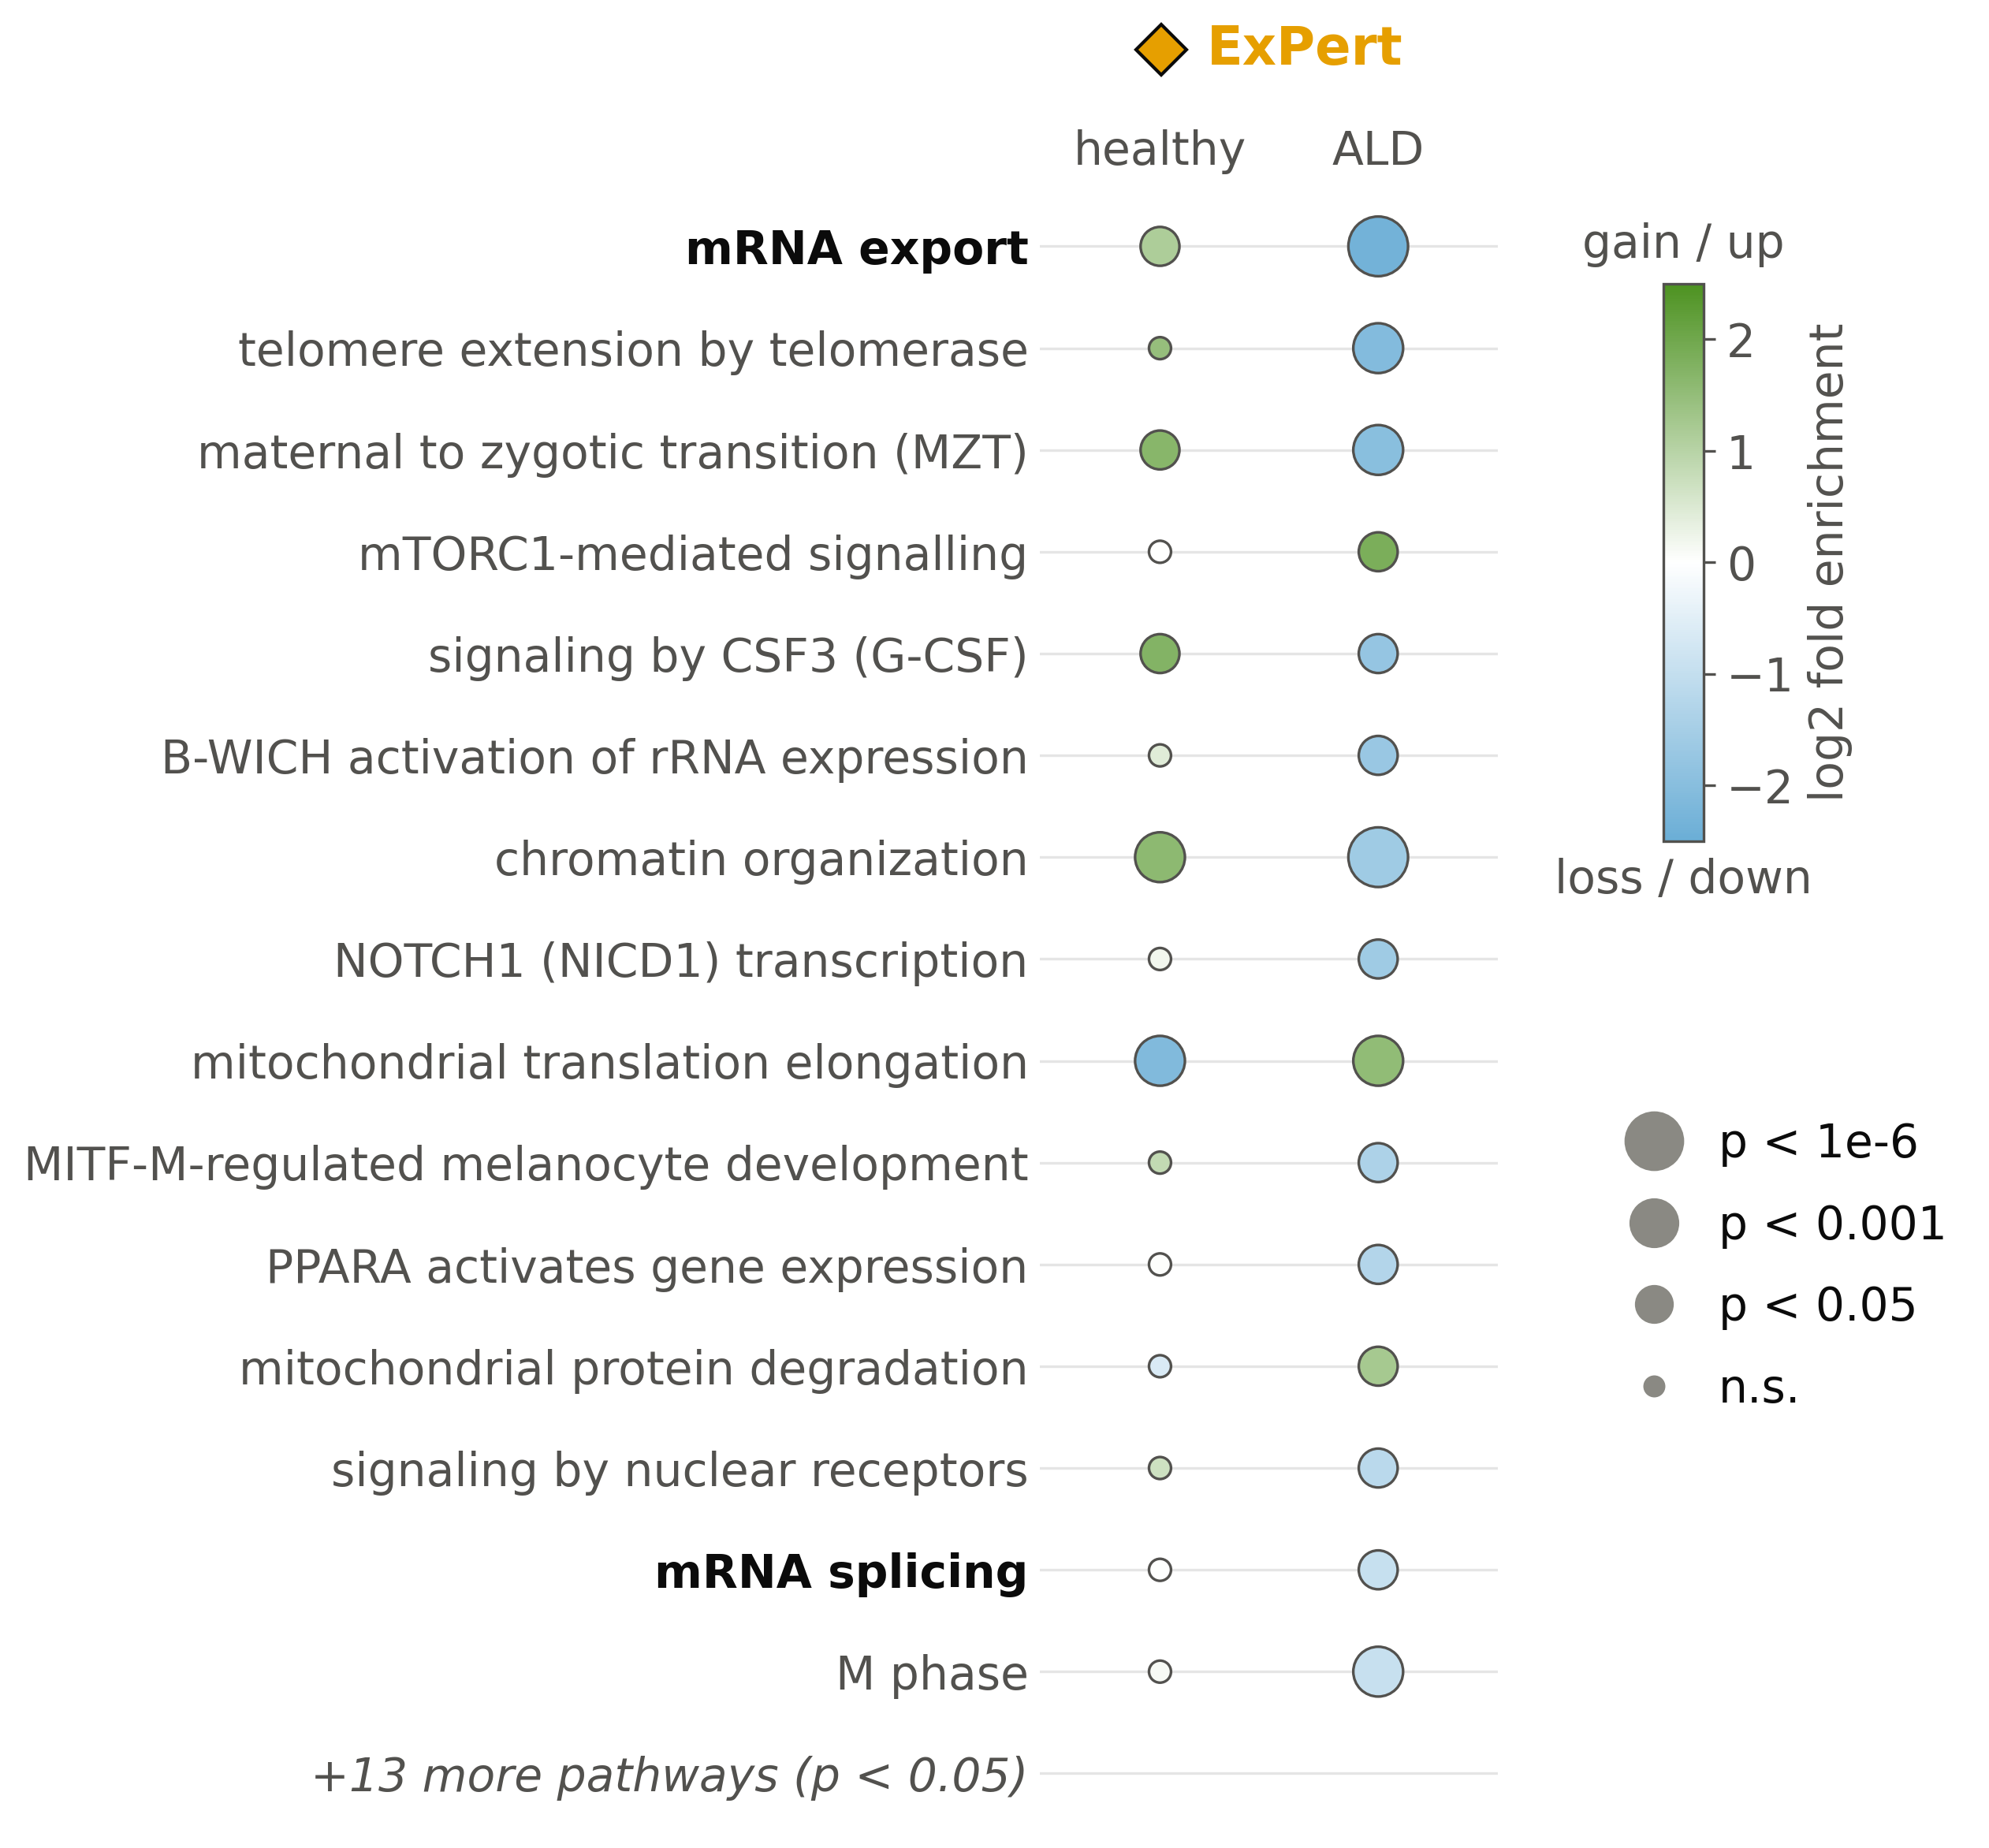

In [6]:
F.panel_pathways(c, rows_e, more_e)
nb.show(OUT, 'fig5e_pathways')

## F — pathways enriched among the top 200 down / up DE genes, ALD hepatocytes

wrote fig5f_pathways_deg


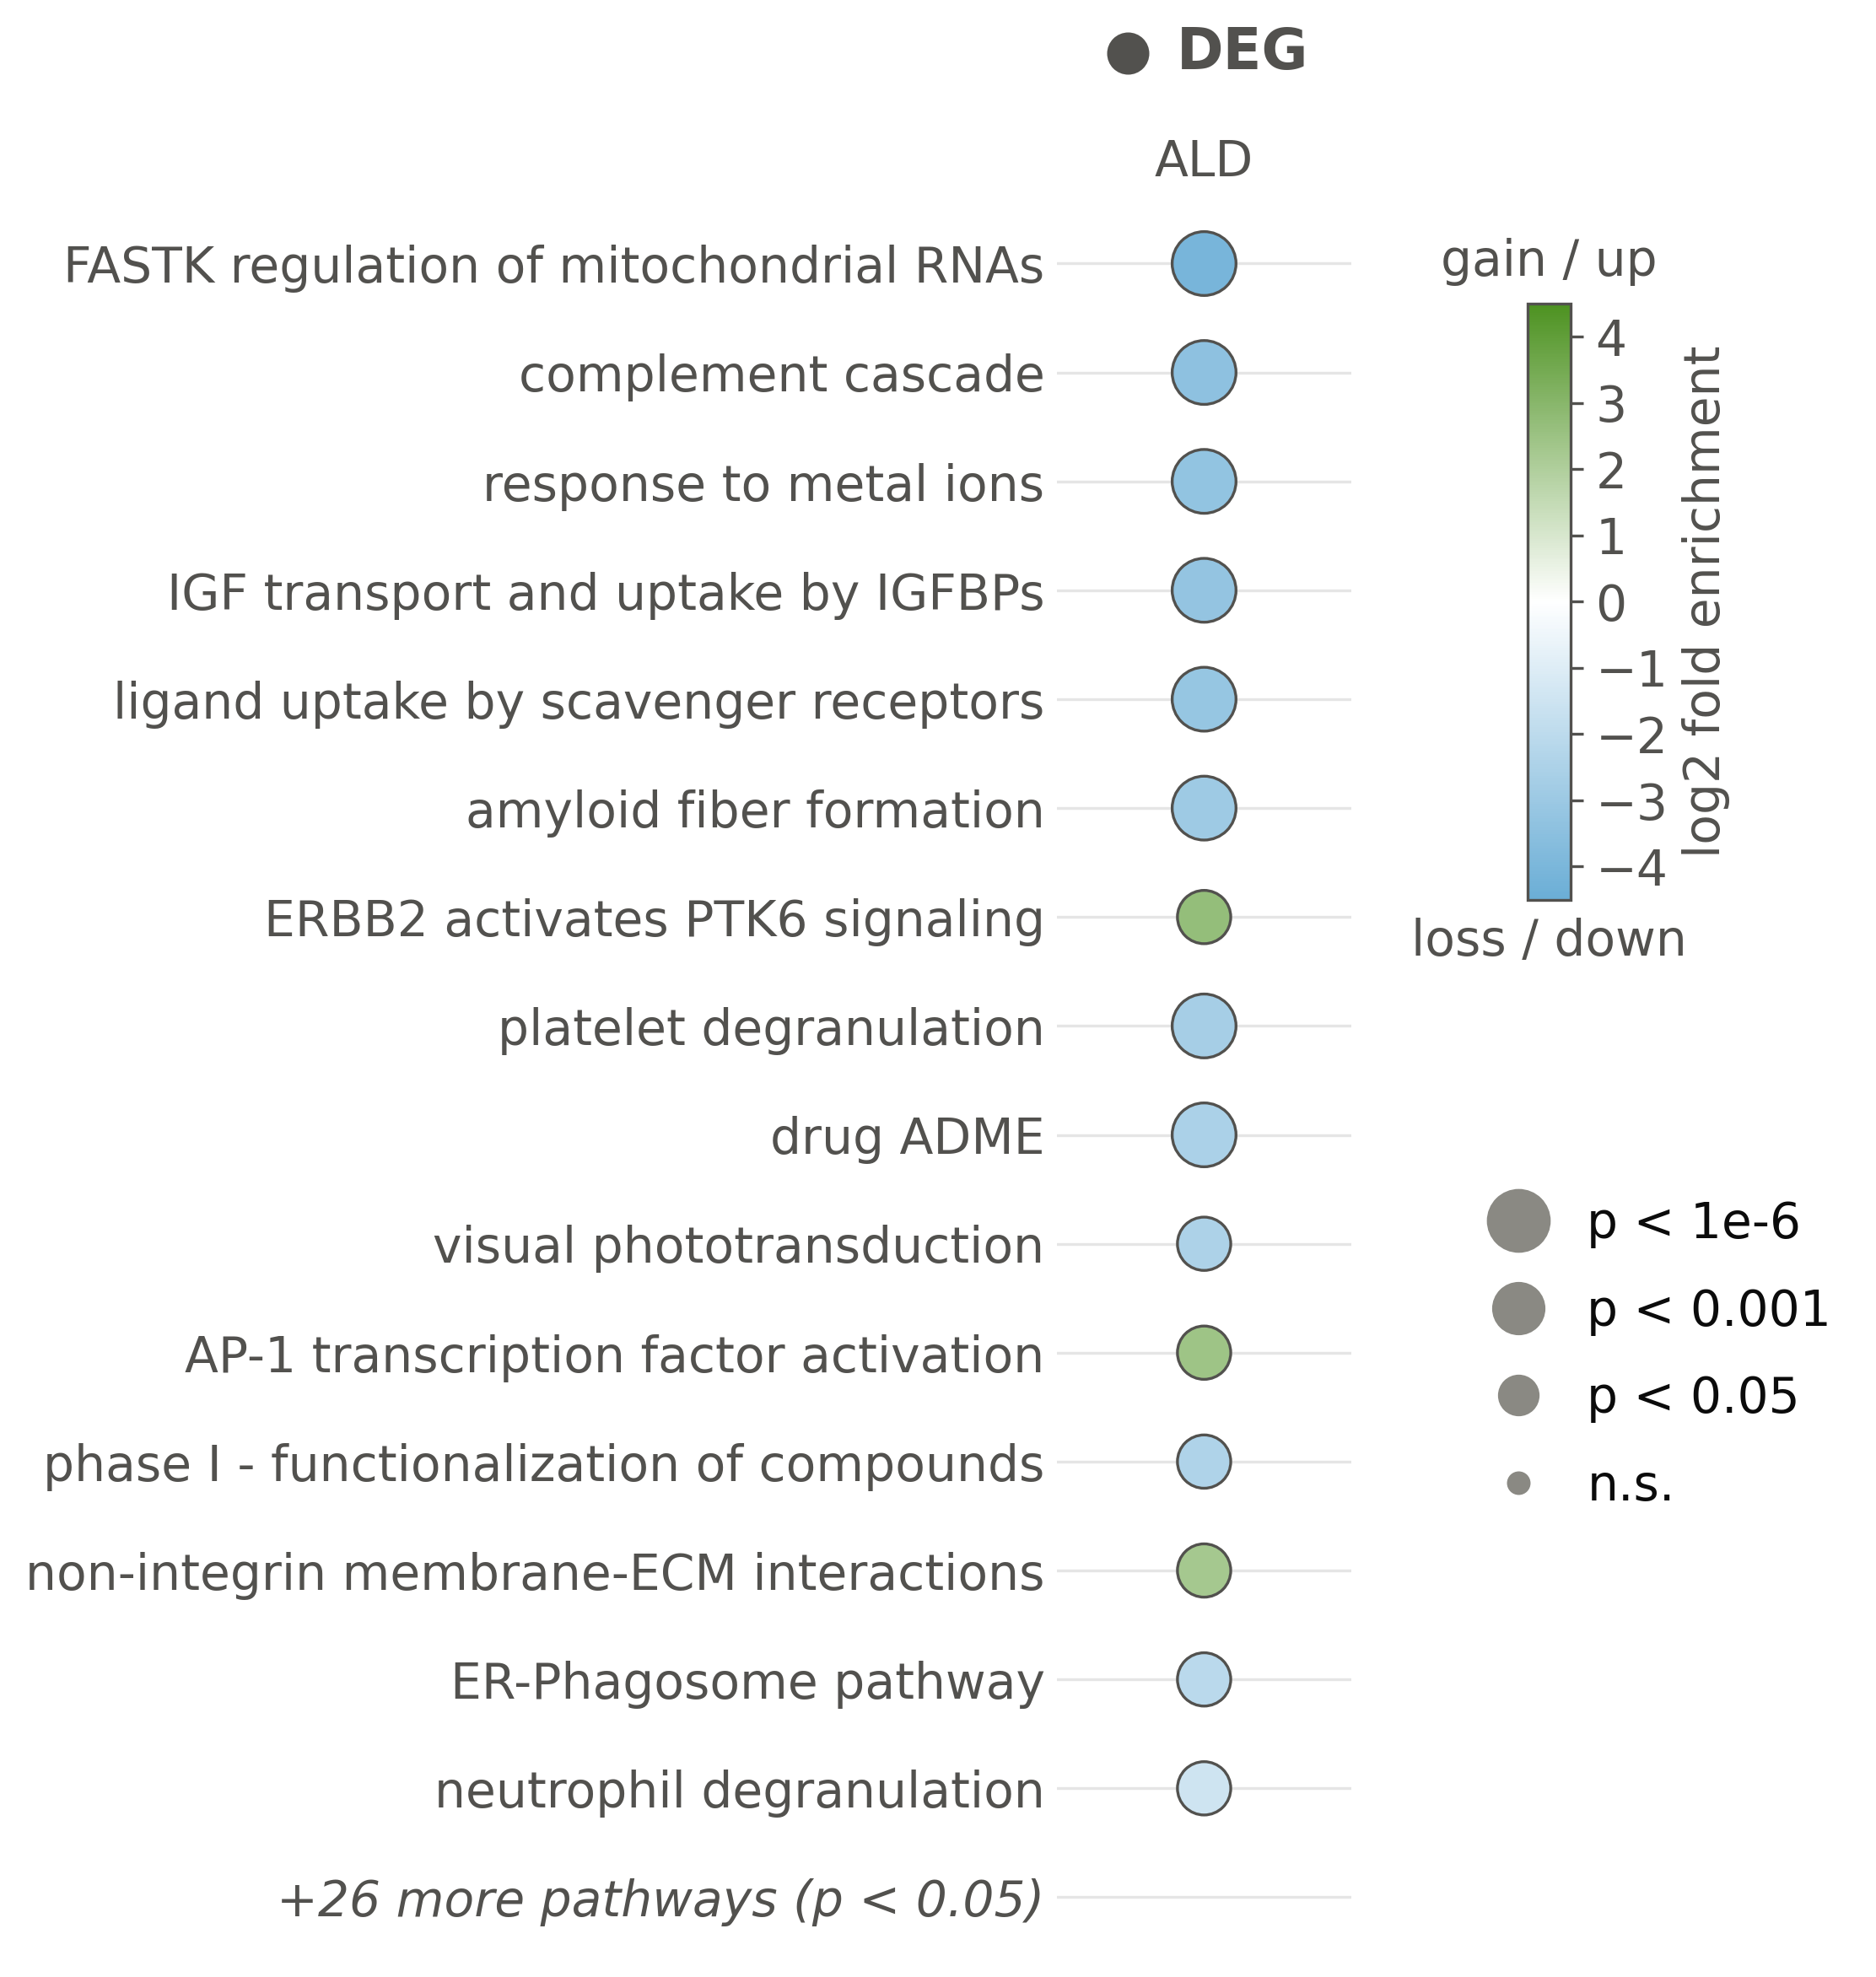

In [7]:
F.panel_pathways_deg(c, rows_f, more_f)
nb.show(OUT, 'fig5f_pathways_deg')

## G — bulk RNA-seq volcanos (AC, AH vs healthy) coloured by ExPert predicted-loss z

wrote fig5g_bulk_volcano


cond  genes_tested  scored_by_expert  n_deg  expert_top  expert_that_are_bulk_DEGs  module_genes  module_DEGs  export_splicing  export_splicing_that_are_DEGs  expert_median_abs_lfc  all_median_abs_lfc
  AC         20835              8567   2664         200                          2           252            0               22                              0                  0.263               0.596
  AH         20835              8567   3435         200                         15           252            0               13                              0                  0.393               0.693


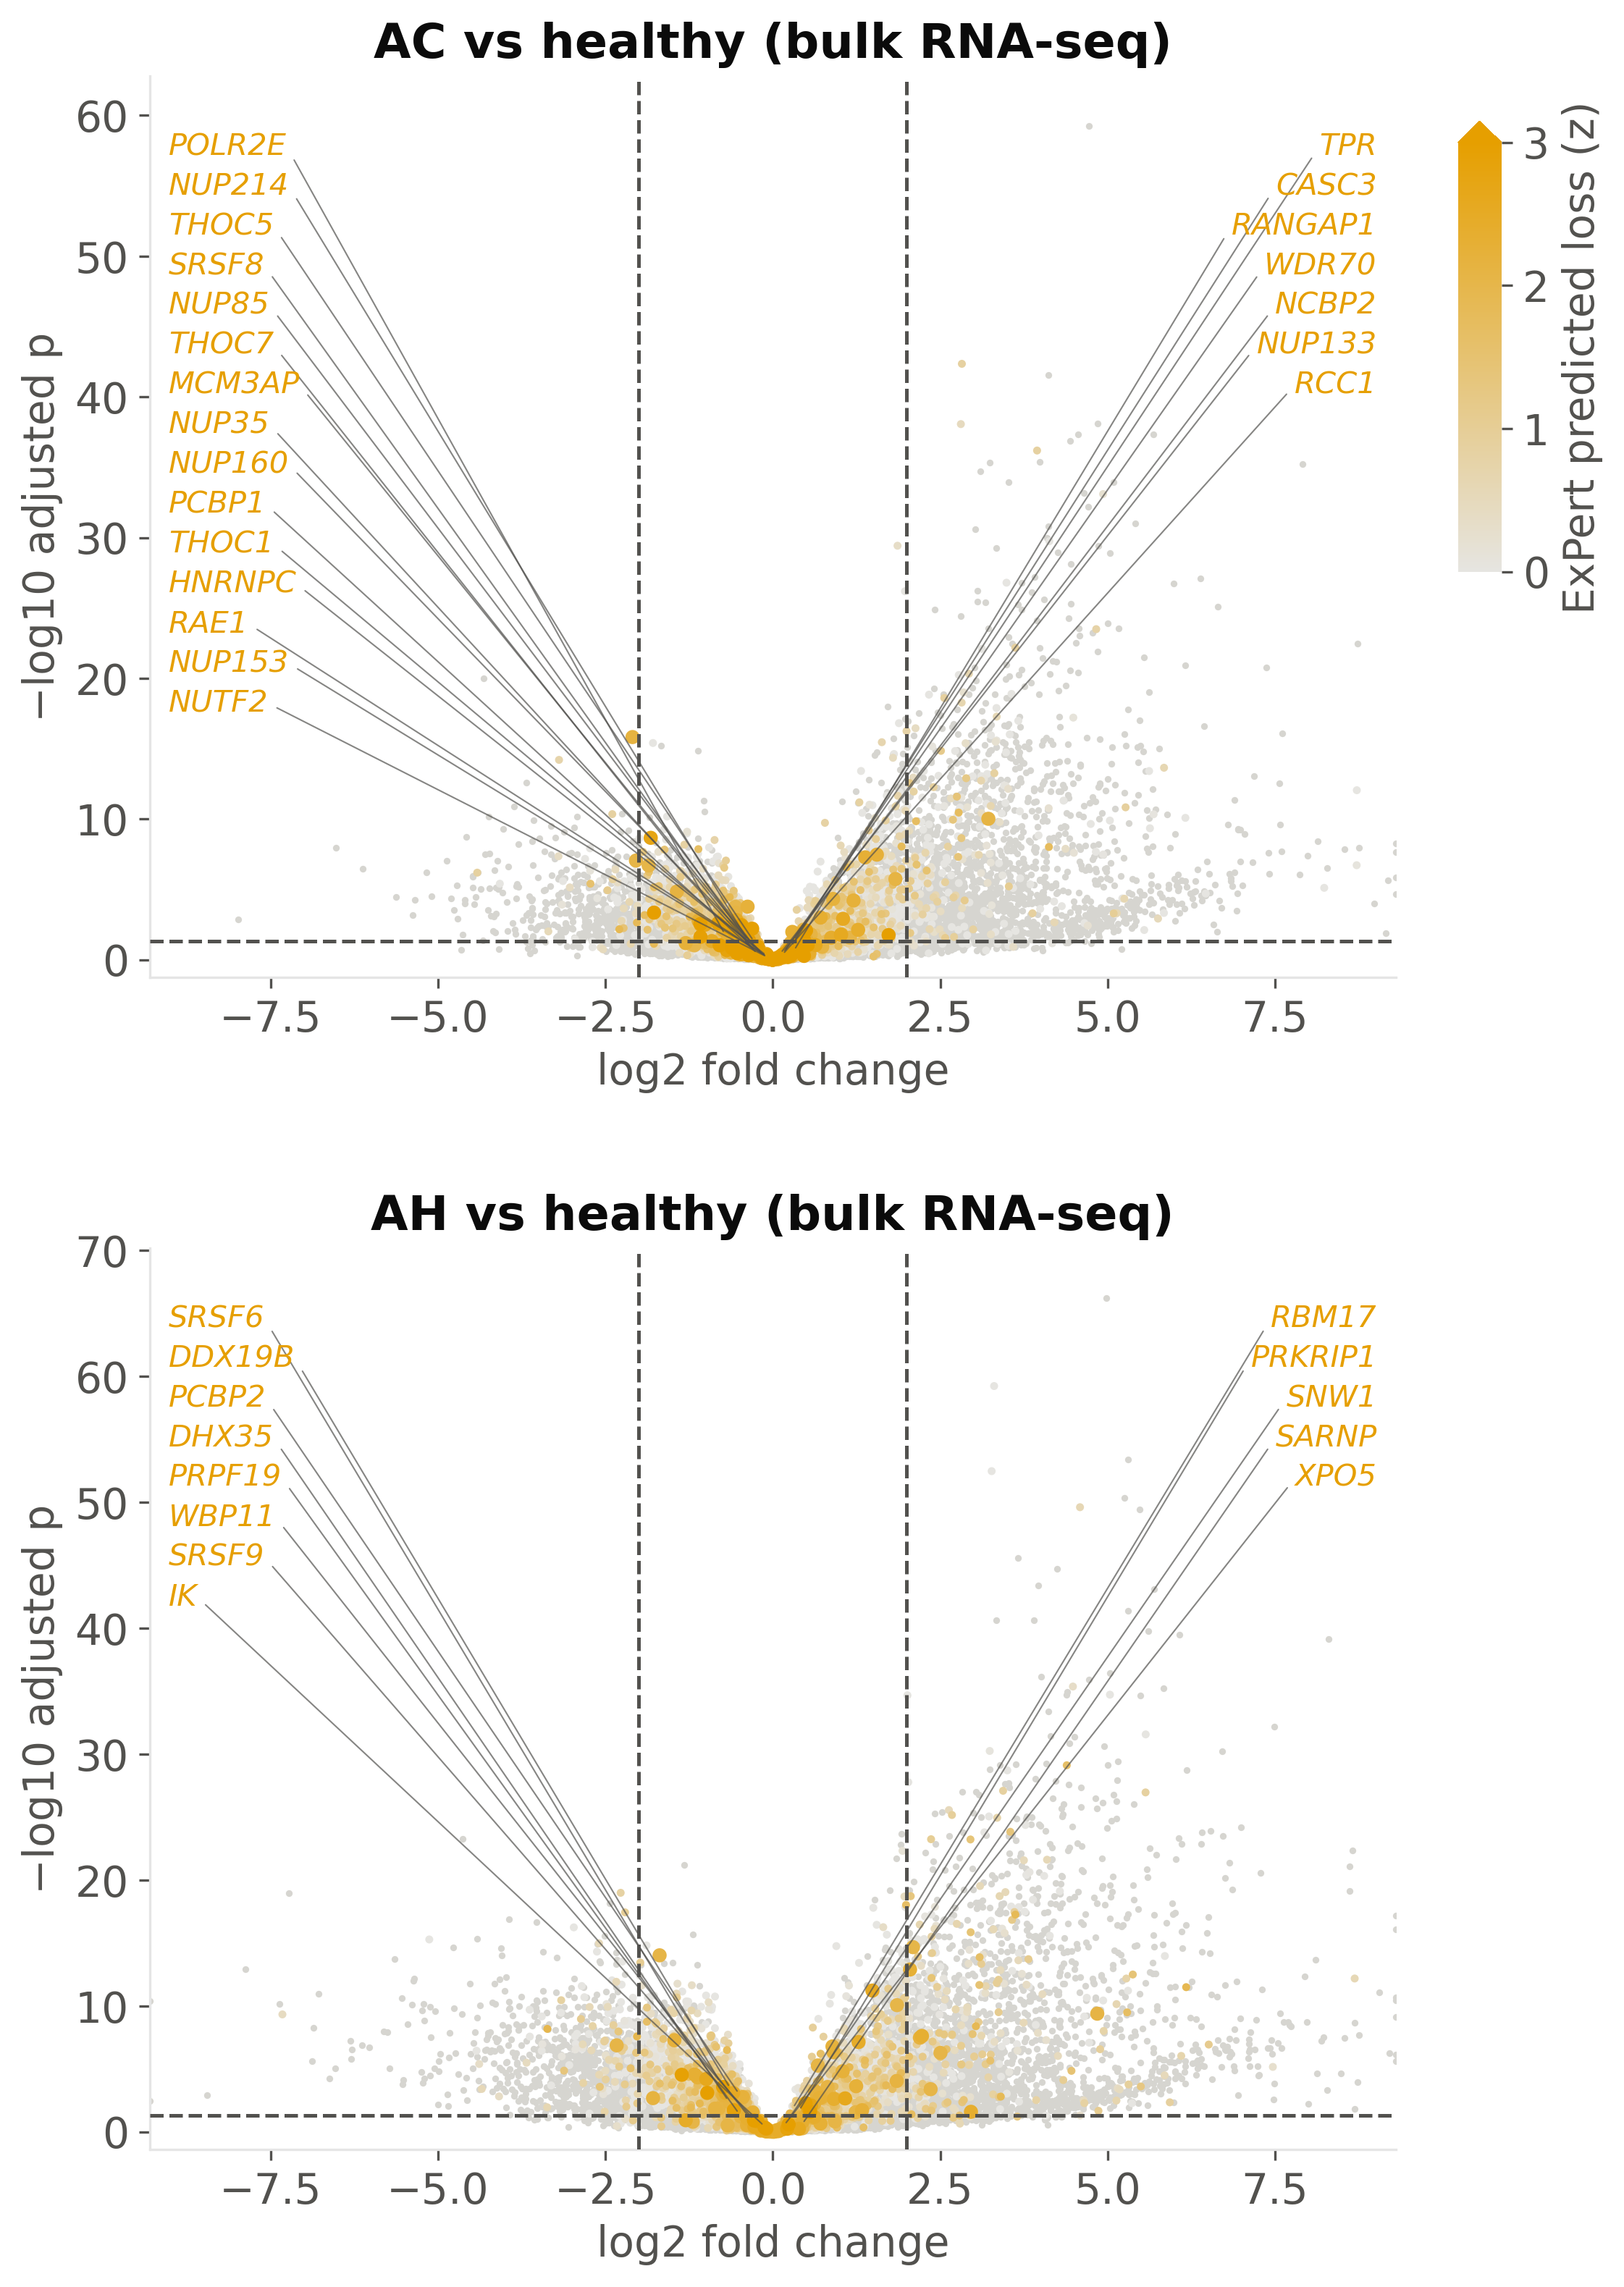

In [8]:
B.volcano(vs, F, b, OUT, c.gs)
nb.show(OUT, 'fig5g_bulk_volcano')

## H — poly(A) RNA-FISH on liver sections

Static micrographs (`fig5h_RNA_FISH.svg`); not drawn by a script.

## I — nuclear : cytoplasmic ratio of poly(A) foci per imaging frame, healthy vs ALD

wrote fig5i_fish_nc


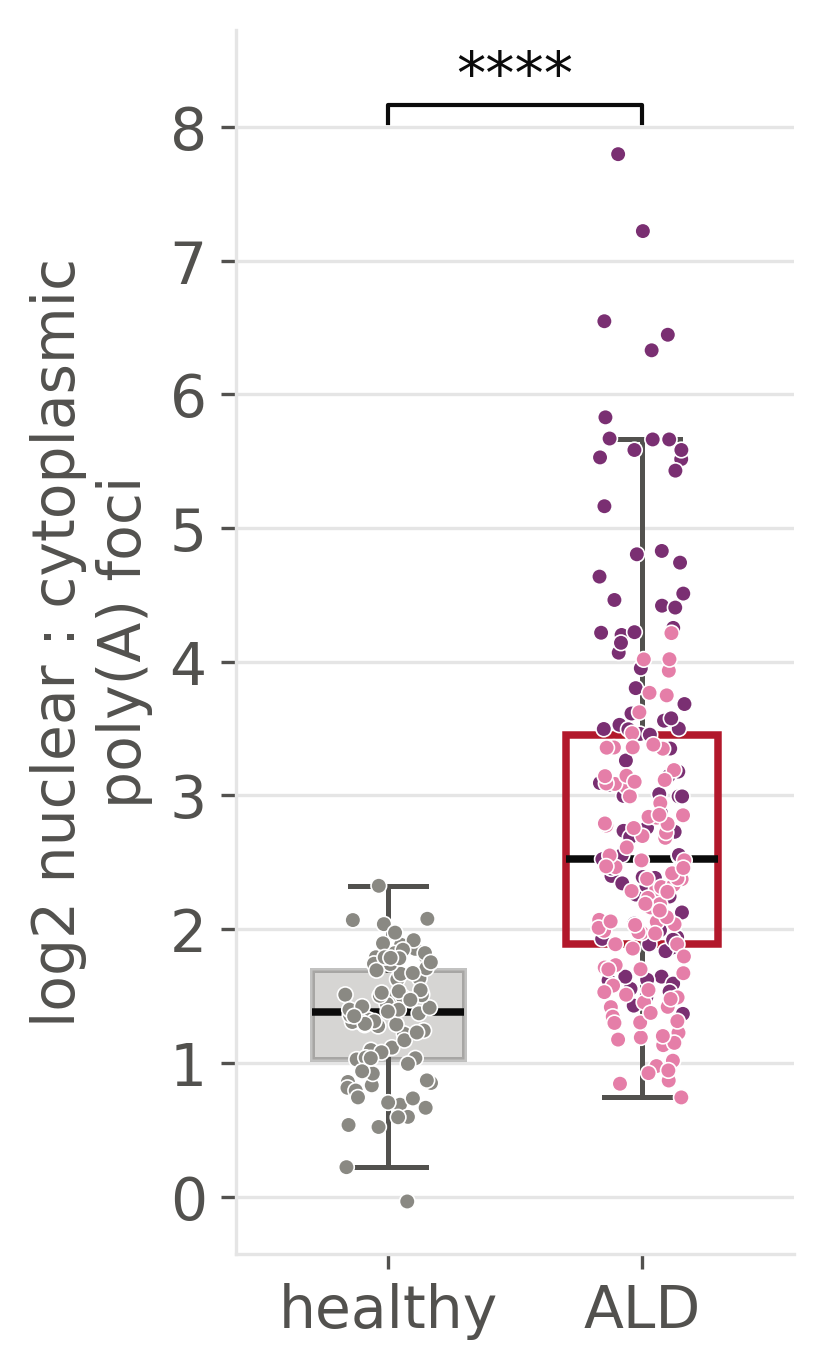

In [9]:
x, tests, _ = FISH.prepare(RAW / 'Microscopy' / 'NuclearEnrichmentQuantification' / 'nuc_puncta_frame_summary_master_raw.csv')
FISH.render(vs, plt, x, tests, 'log2nc', FISH.YLAB, 'fig5i_fish_nc', FISH.MAIN, OUT, np.random.default_rng(0))
nb.show(OUT, 'fig5i_fish_nc')

## J — diameter of DAPI-segmented hepatocyte nuclei, healthy vs ALD

wrote fig5j_nuclei_diameter


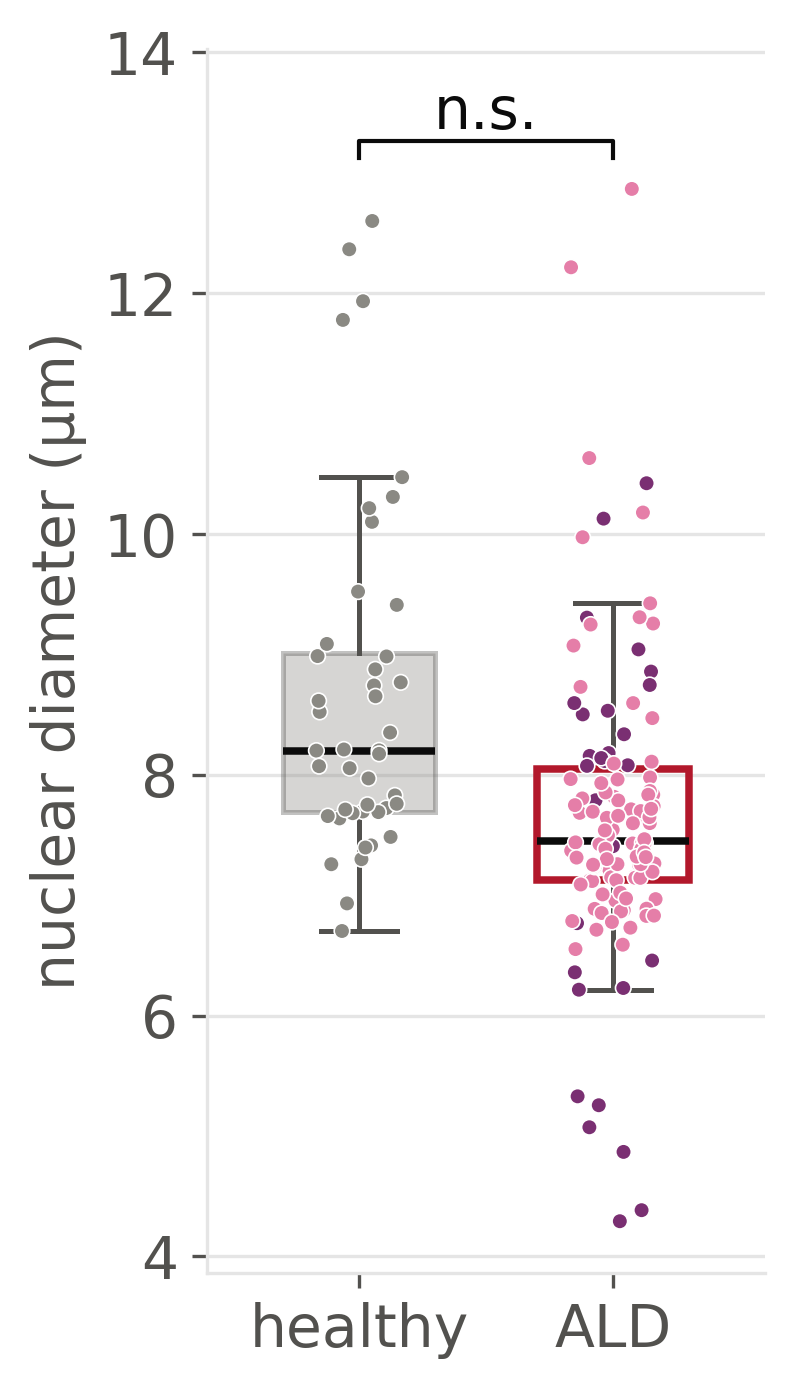

In [10]:
x = NUC.load(RAW / 'Microscopy' / 'NuclearMorphometry' / 'NucleiMeasurements.csv')
NUC.plot(vs, plt, x, 'average_diameter', ['Healthy', 'ALD'], [0, 1], [('Healthy', 'ALD')], OUT,
         'fig5j_nuclei_diameter', True, medians=False)
nb.show(OUT, 'fig5j_nuclei_diameter')

## K — bulk volcanos with significantly spliced genes, and the ExPert top 20 per condition

wrote fig5k_splicing


cond  k  universe  family_hit_rate  observed  null_mean  null_lo  null_hi     p  exact_gene_hits  export_family_genes  export_family_hits
  AC 20      8567            0.404         9      8.084      4.0     12.0 0.418                1                    3                   2
  AH 20      8567            0.449         9      8.968      5.0     13.0 0.575                2                    3                   3


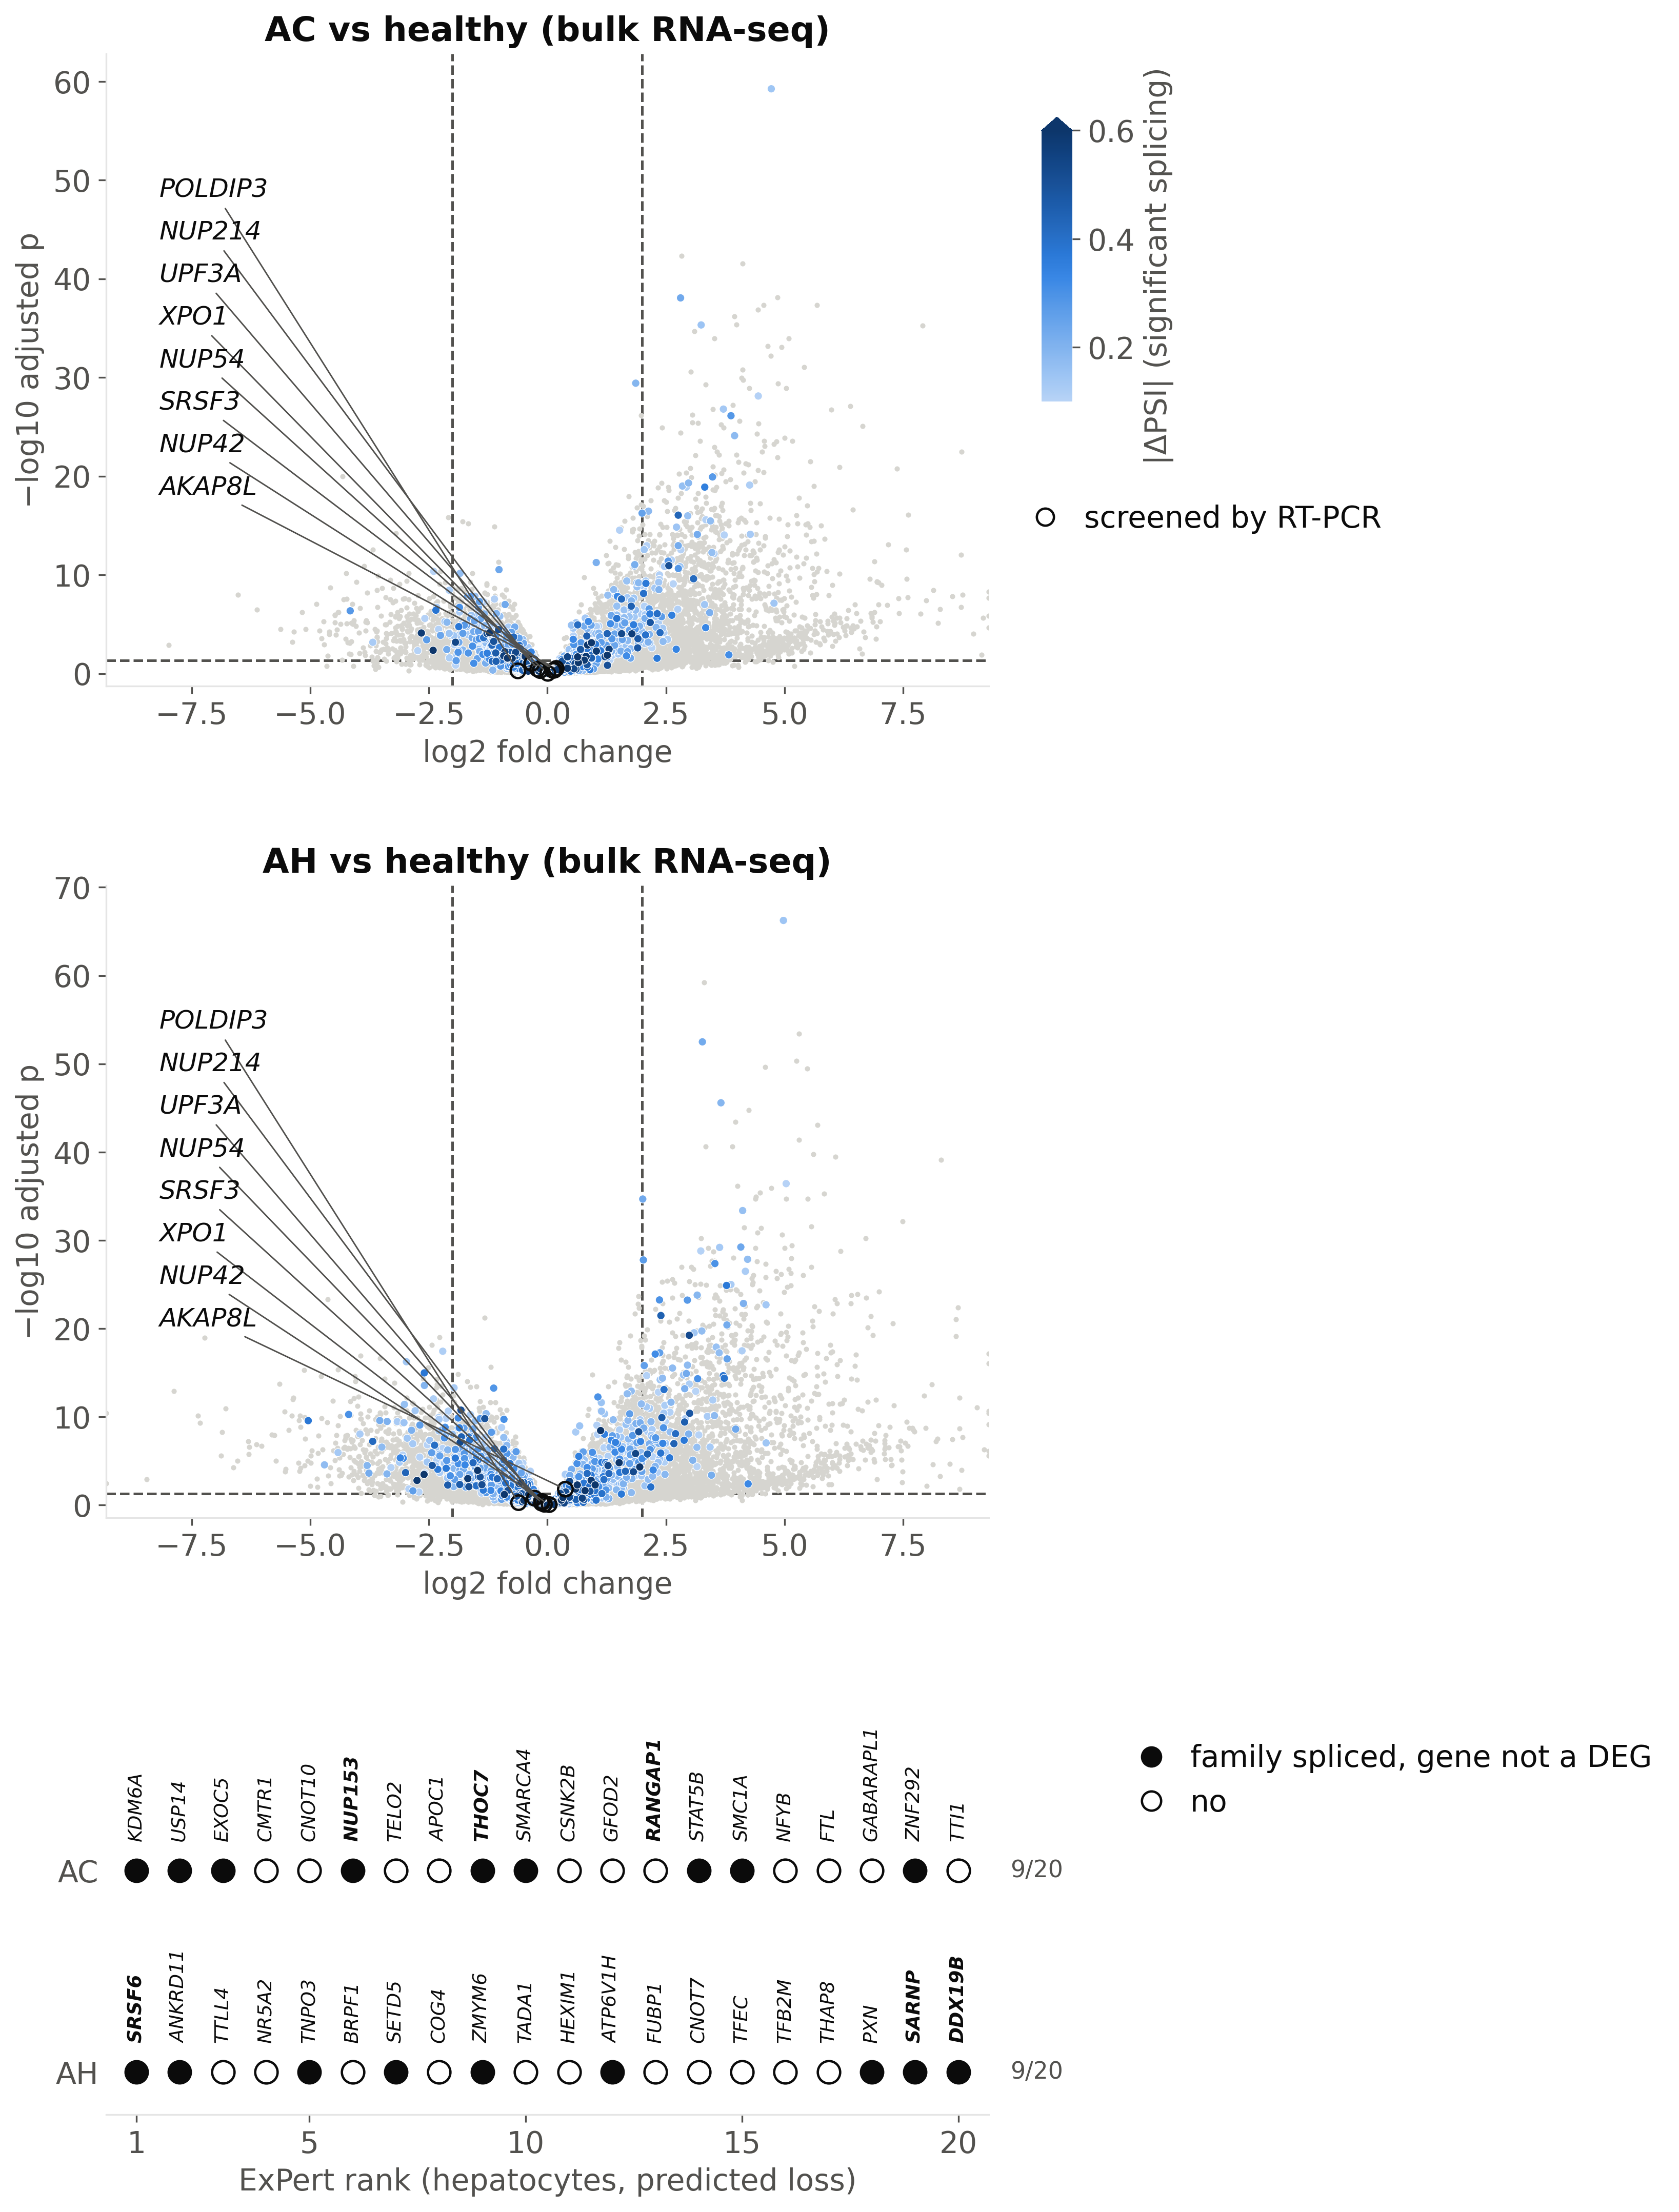

In [11]:
B.splice_volcano(vs, F, b, OUT, c.gs)
nb.show(OUT, 'fig5k_splicing')

## L — predicted-loss z of the mRNA export machinery families, healthy vs ALD hepatocytes

wrote fig5l_export_families


           family cond  k  named  mean_z  mean_healthy        p   p_bh
      NUP complex  ALD 28      9    0.47     -0.187543 0.010257 0.0615
    TREX / TREX-2  ALD 14      5    0.65     -0.690299 0.024536 0.0736
        Ran cycle  ALD  5      3    0.70     -0.269077 0.125000 0.1875
EJC / cap-binding  ALD 11      2    0.38     -0.173423 0.278320 0.2783
      SR proteins  ALD 11      2    0.20     -0.589585 0.041992 0.0840
        exportins  ALD  8      1    0.21     -0.338230 0.250000 0.2783


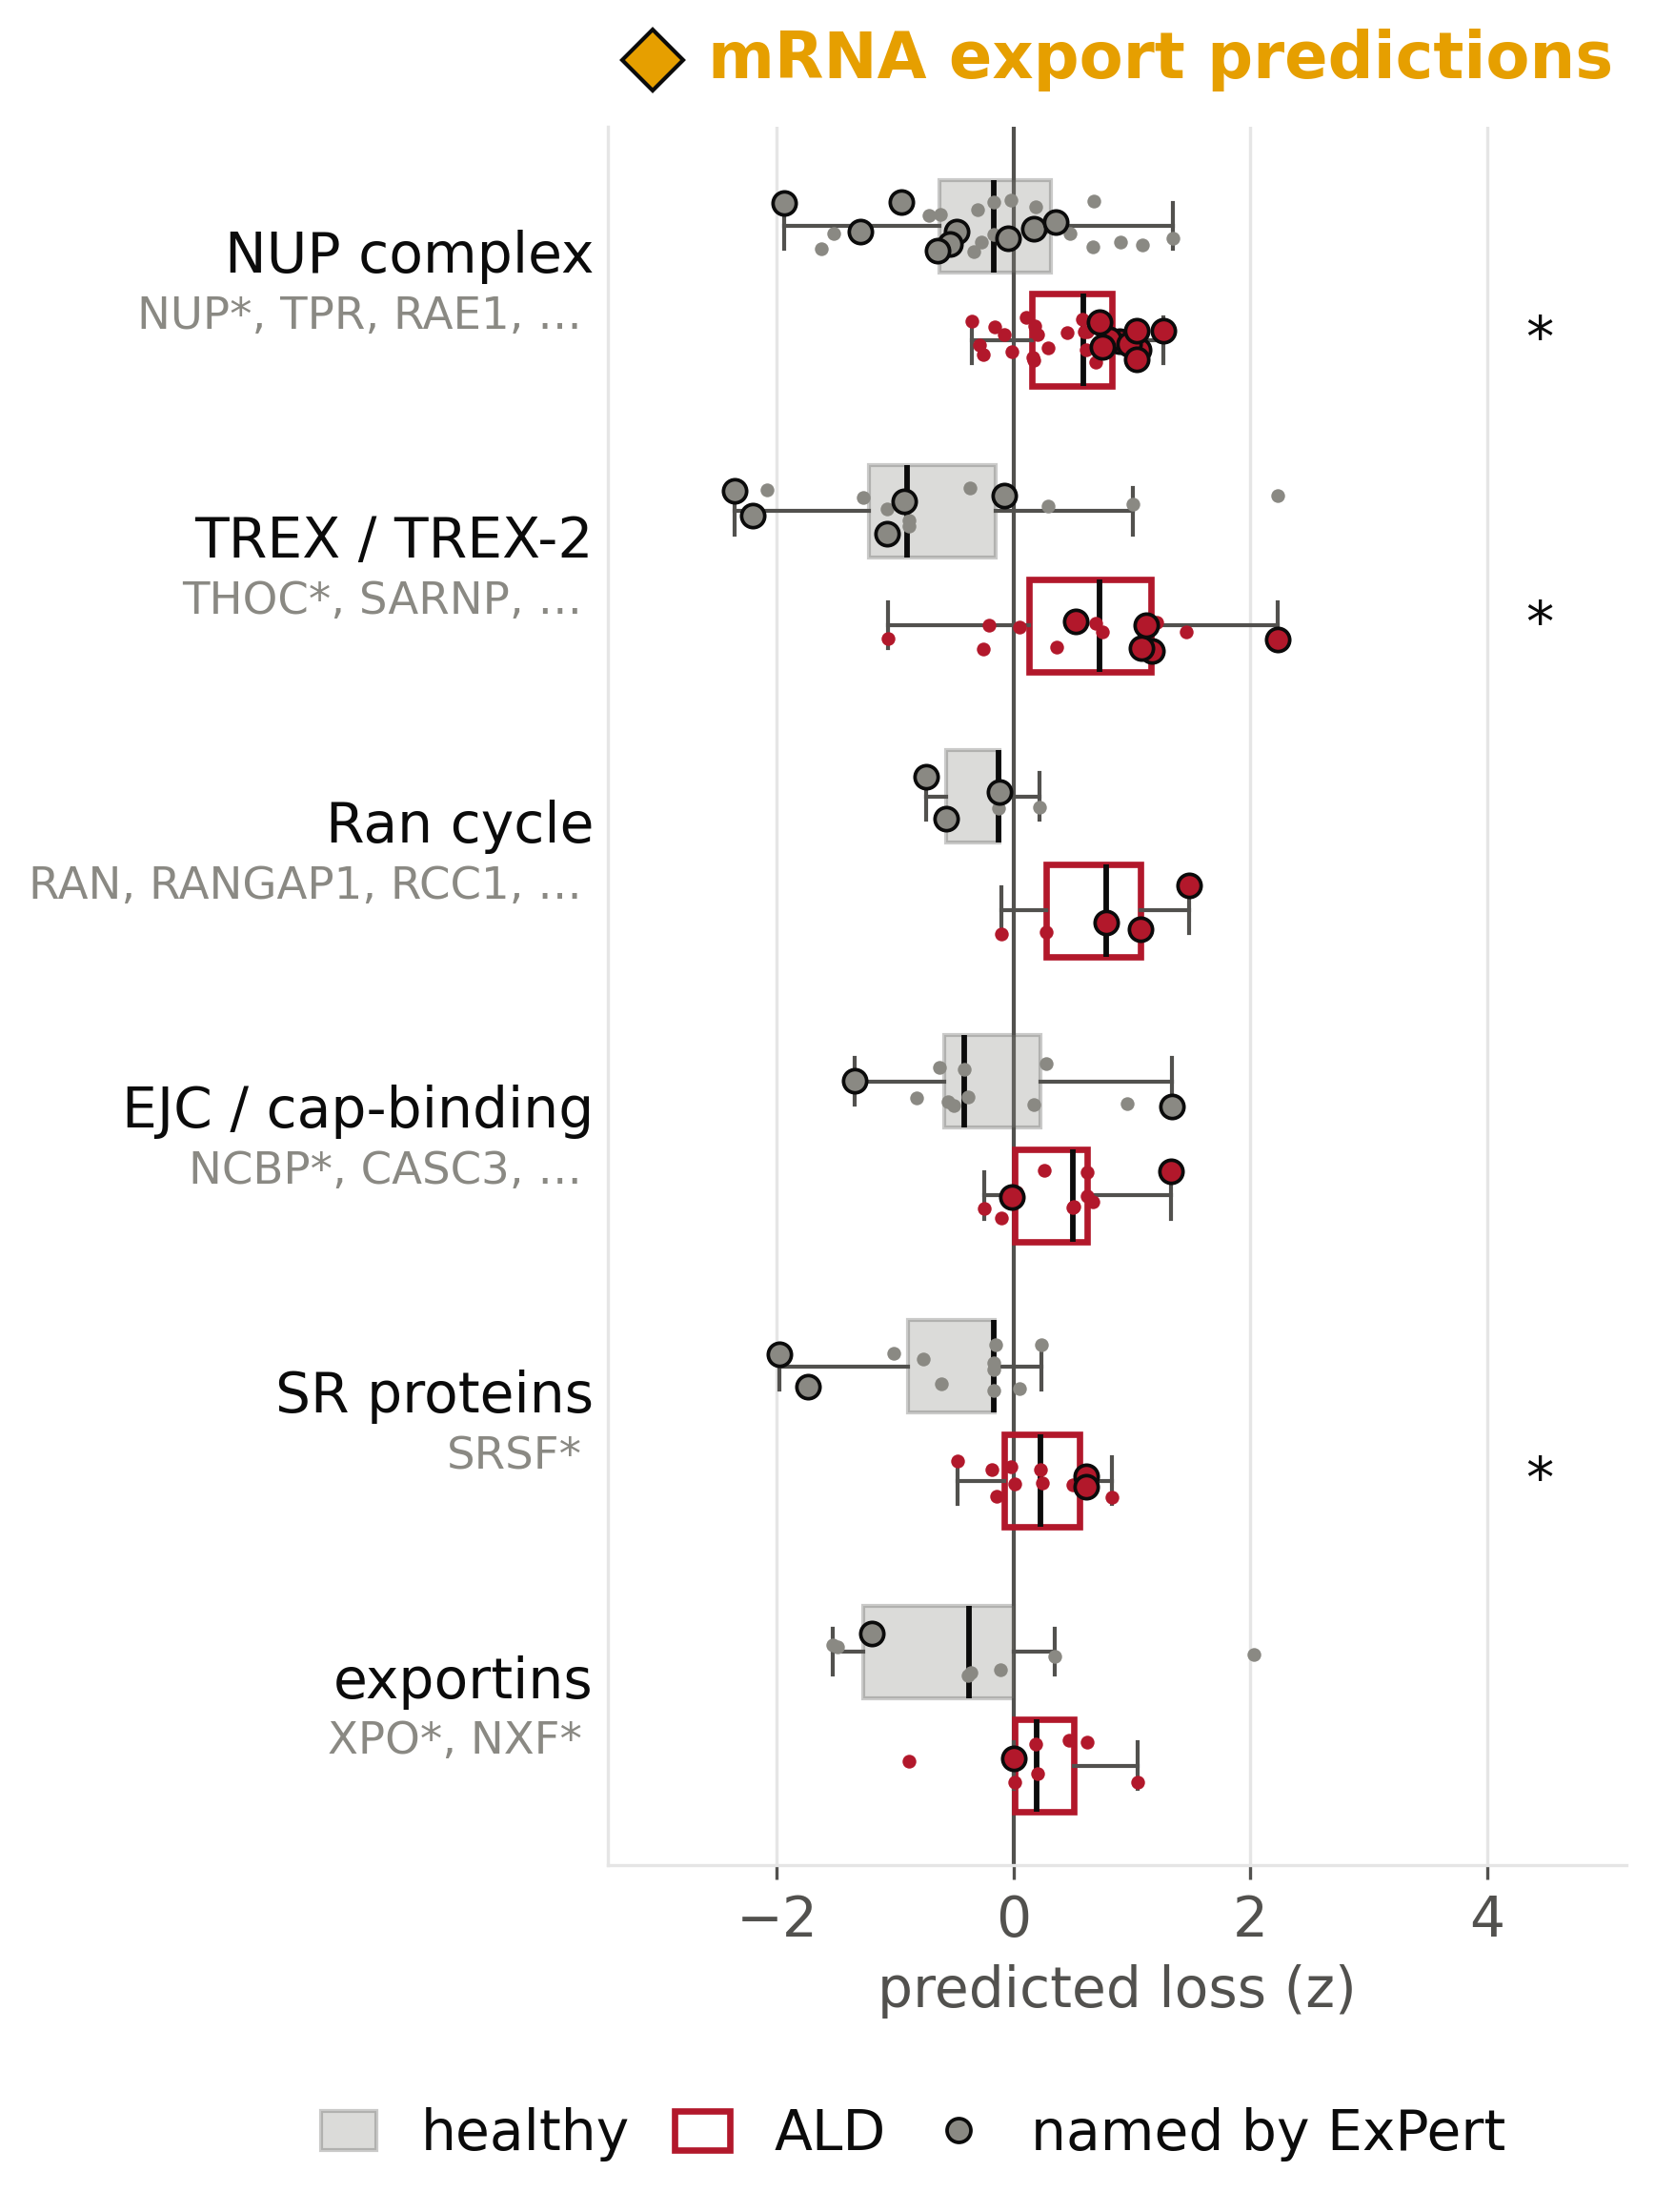

In [12]:
F.family_bars(vs, c.d, OUT, c.cc, a, c.gs, name='fig5l_export_families', pair=True)
nb.show(OUT, 'fig5l_export_families')

## M — RT-PCR ΔPSI of eight exons vs the healthy median

The gels on the left (`fig5m_SpliceAssay_gels.svg`) are static images; only the ΔPSI grid is drawn.

wrote fig5m_psi


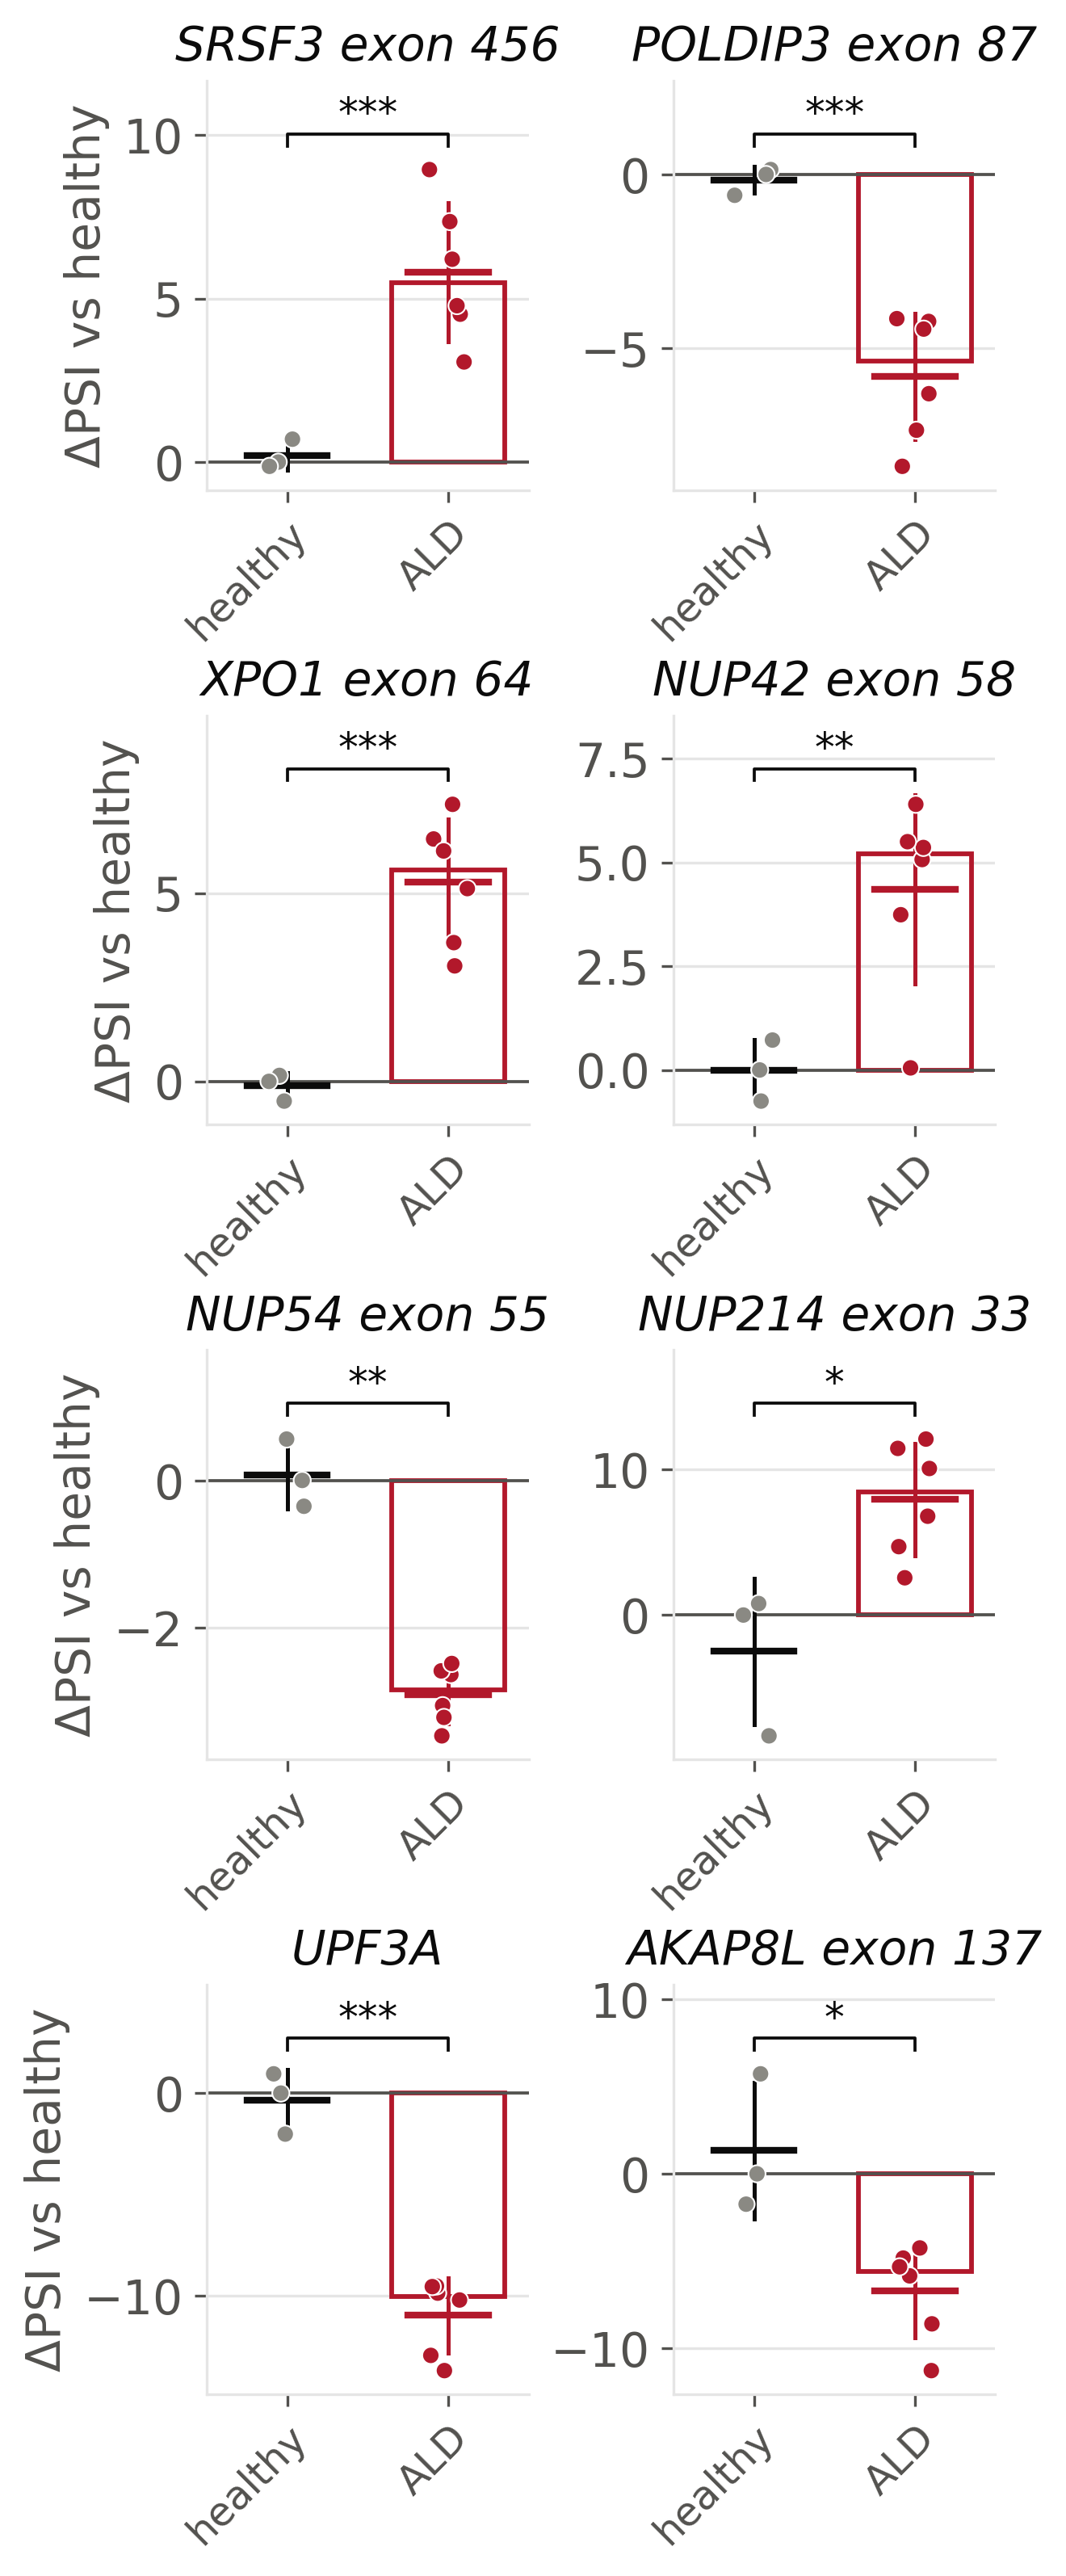

In [13]:
p = PSI.parser().parse_args(['--prism', str(RAW / 'Gel' / 'Qty.prism'), '--fig-dir', str(OUT), '--src-dir', str(SRC),
                             '--vizstyle-root', str(nb.STYLE)])
x, exons, tests = PSI.prepare(p.prism, p.order)
PSI._grid(vs, plt, x, exons, tests, PSI.CC, p, ['Healthy', 'ALD'], [0, 1], 'fig5m_psi', OUT)
nb.show(OUT, 'fig5m_psi')